__Описание проекта__:
<div style="background-color: white; color: maroon;">
    HR-аналитики компании «Работа с заботой» помогают бизнесу оптимизировать управление персоналом: бизнес предоставляет данные, а аналитики предлагают, как избежать финансовых потерь и оттока сотрудников. В этом HR-аналитикам пригодится машинное обучение, с помощью которого получится быстрее и точнее отвечать на вопросы бизнеса.
</div>

<div style="background-color: white; color: olive;">
    Итак, предо мною сдвоенная задача:
    <br/>
    <br/>
    1) Построить модель, которая сможет предсказать уровень удовлетворённости сотрудника на основе данных заказчика;
    <br/>
    2) Построить модель, которая сможет на основе данных заказчика предсказать то, что сотрудник уволится из компании.
</div>

<div style="background-color: white; color: olive;">
    Но для начала установим план выполнения работ:
    <br/>
    <br/>
    <br/>
    Задача 1: предсказание уровня удовлетворённости сотрудника
    <br/>
    1) Загрузка данных;
    <br/>
    2) Предобработка данных;
    <br/>
    3) Исследовательский анализ данных;
    <br/>
    4) Подготовка данных;
    <br/>
    5) Обучение моделей;
    <br/>
    6) Оформление выводов.
    <br/>
    <br/>
    <br/>
    Задача 2: предсказание увольнения сотрудника из компании
    <br/>
    1) Загрузка данных;
    <br/>
    2) Предобработка данных;
    <br/>
    3) Исследовательский анализ данных;
    <br/>
    4) Добавление нового входного признака;
    <br/>
    5) Подготовка данных;
    <br/>
    6) Обучение модели;
    <br/>
    7) Выводы.
</div>

<div style="background-color: white; color: olive;">
    Теперь уточним, с какими данными будем иметь дело (информация о столбцах набора данных):
    <br/>
    <br/>
    <br/>
    id — уникальный идентификатор сотрудника;
    <br/>
    dept — отдел, в котором работает сотрудник;
    <br/>
    level — уровень занимаемой должности;
    <br/>
    workload — уровень загруженности сотрудника;
    <br/>
    employment_years — длительность работы в компании (в годах);
    <br/>
    last_year_promo — показывает, было ли повышение за последний год;
    <br/>
    last_year_violations — показывает, нарушал ли сотрудник трудовой договор за последний год;
    <br/>
    supervisor_evaluation — оценка качества работы сотрудника, которую дал руководитель;
    <br/>
    salary — ежемесячная зарплата сотрудника;
    <br/>
    job_satisfaction_rate — уровень удовлетворённости сотрудника работой в компании, целевой признак;
    <br/>
    quit — показывает, покинул ли сотрудник компанию.
</div>

<div style="background-color: white; color: olive;">
    Сперва все необходимые библиотеки подключим.
</div>

In [1]:
!pip install phik -q
!pip install shap -q
!pip install category_encoders -q

import pandas as pd
import io
import requests
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import scipy.stats as stats

from scipy.stats import contingency, chi2_contingency
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import (OneHotEncoder,
                                   StandardScaler,
                                   LabelEncoder,
                                   OrdinalEncoder)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score,
                             recall_score,
                             precision_score,
                             confusion_matrix,
                             classification_report,
                             r2_score, mean_squared_error,
                             mean_absolute_error,
                             precision_recall_curve,
                             make_scorer,
                             f1_score,
                             roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.svm import SVC, SVR
from category_encoders import TargetEncoder
from sklearn.ensemble import (RandomForestRegressor,
                              GradientBoostingRegressor,
                              RandomForestClassifier,
                              GradientBoostingClassifier)
from warnings import simplefilter
# ignore all future warnings
simplefilter(action='ignore', category=FutureWarning)
from phik import resources, report
import shap

## Загрузка данных

<div style="background-color: white; color: olive;">
    Теперь импортируем датасеты.
</div>

In [2]:
url_1 = 'https://drive.google.com/uc?export=download&id=1hJypwro0QOO6hSz_B5vK7ZIQ0Mf1kj0r'
response_1 = requests.get(url_1)
data_1 = io.StringIO(response_1.text)
train_job_satisfaction_rate = pd.read_csv(data_1)

In [3]:
display(train_job_satisfaction_rate)

,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,job_satisfaction_rate
0,155278,sales,junior,medium,2,no,no,1,24000,0.58
1,653870,hr,junior,high,2,no,no,5,38400,0.76
2,184592,sales,junior,low,1,no,no,2,12000,0.11
3,171431,technology,junior,low,4,no,no,2,18000,0.37
4,693419,hr,junior,medium,1,no,no,3,22800,0.20
...,...,...,...,...,...,...,...,...,...,...
3995,457950,technology,junior,high,2,no,no,3,46800,0.45
3996,957499,sales,junior,medium,2,no,no,4,21600,0.68
3997,533318,sales,middle,low,7,no,no,5,24000,0.76
3998,706868,sales,junior,medium,2,no,no,3,24000,0.48


In [4]:
url_2 = 'https://drive.google.com/uc?export=download&id=1u8HYVIrX9nQffhPm5noYCNs9-QSdt_nZ'
response_2 = requests.get(url_2)
data_2 = io.StringIO(response_2.text)
test_features = pd.read_csv(data_2)

In [5]:
display(test_features)

,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary
0,485046,marketing,junior,medium,2,no,no,5,28800
1,686555,hr,junior,medium,1,no,no,4,30000
2,467458,sales,middle,low,5,no,no,4,19200
3,418655,sales,middle,low,6,no,no,4,19200
4,789145,hr,middle,medium,5,no,no,5,40800
...,...,...,...,...,...,...,...,...,...
1995,393147,marketing,junior,low,3,no,no,3,20400
1996,109582,technology,middle,low,3,no,no,2,21600
1997,305653,technology,junior,low,1,no,no,3,14400
1998,160233,technology,middle,low,8,no,no,1,32400


In [6]:
url_3 = 'https://drive.google.com/uc?export=download&id=1nTPwFnIsfLNZqJ7Z751DsS4tohuwGV_l'
response_3 = requests.get(url_3)
data_3 = io.StringIO(response_3.text)
test_target_job_satisfaction_rate = pd.read_csv(data_3)

In [7]:
display(test_target_job_satisfaction_rate)

,id,job_satisfaction_rate
0,130604,0.74
1,825977,0.75
2,418490,0.60
3,555320,0.72
4,826430,0.08
...,...,...
1995,405257,0.28
1996,370925,0.21
1997,857722,0.39
1998,303402,0.26


## Предобработка данных

<div style="background-color: white; color: olive;">
    Пришло время взглянуть на наборы данные подробнее.
</div>

In [8]:
train_job_satisfaction_rate.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     4000 non-null   int64  
 1   dept                   3994 non-null   object 
 2   level                  3996 non-null   object 
 3   workload               4000 non-null   object 
 4   employment_years       4000 non-null   int64  
 5   last_year_promo        4000 non-null   object 
 6   last_year_violations   4000 non-null   object 
 7   supervisor_evaluation  4000 non-null   int64  
 8   salary                 4000 non-null   int64  
 9   job_satisfaction_rate  4000 non-null   float64
dtypes: float64(1), int64(4), object(5)
memory usage: 312.6+ KB


<div style="background-color: white; color: olive;">
    На данном этапе можно осознать, что в двух столбцах имеются карйне редкие пропущенные значения. Сперва взглянем на уникальные значения категориальных признаков, а затем посмотрим на пропущенные. Типы данных вполне ожидаемые и коррелирующие с той информацией, которая записана в столбцах датасета.
</div>

In [9]:
display(train_job_satisfaction_rate['dept'].unique())

array(['sales', 'hr', 'technology', 'purchasing', 'marketing', nan],
      dtype=object)

In [10]:
display(train_job_satisfaction_rate['level'].unique())

array(['junior', 'middle', 'sinior', nan], dtype=object)

<div style="background-color: white; color: olive;">
    "sinior" для меня странновато звучит, ибо обычно это "senior". Надо будет сравнить с прочими датасетами и, если что, поправить. Пока что просто смотрим, поправим после.
</div>

In [11]:
display(train_job_satisfaction_rate['workload'].unique())

array(['medium', 'high', 'low'], dtype=object)

In [12]:
display(train_job_satisfaction_rate['last_year_promo'].unique())

array(['no', 'yes'], dtype=object)

In [13]:
display(train_job_satisfaction_rate['last_year_violations'].unique())

array(['no', 'yes'], dtype=object)

<div style="background-color: white; color: olive;">
    Столбцы 'last_year_promo' и 'last_year_violations' бинарные, можно будет заменить на True/False (boolean).
</div>

<div style="background-color: white; color: olive;">
    Взглянем аналогичным образом на входные признаки тестовой выборки (test_features) и на целевой признак тестовой выборки (test_target_job_satisfaction_rate)
</div>

In [14]:
test_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   id                     2000 non-null   int64 
 1   dept                   1998 non-null   object
 2   level                  1999 non-null   object
 3   workload               2000 non-null   object
 4   employment_years       2000 non-null   int64 
 5   last_year_promo        2000 non-null   object
 6   last_year_violations   2000 non-null   object
 7   supervisor_evaluation  2000 non-null   int64 
 8   salary                 2000 non-null   int64 
dtypes: int64(4), object(5)
memory usage: 140.8+ KB


In [15]:
test_target_job_satisfaction_rate.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     2000 non-null   int64  
 1   job_satisfaction_rate  2000 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 31.4 KB


In [16]:
display(test_features['dept'].unique())
display(test_features[test_features['dept'] == ' '])
test_features['dept'] = test_features['dept'].replace(' ', np.nan)

array(['marketing', 'hr', 'sales', 'purchasing', 'technology', nan, ' '],
      dtype=object)

,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary
1699,822186,,middle,medium,3,no,no,4,38400


In [17]:
display(test_features['level'].unique())

array(['junior', 'middle', 'sinior', nan], dtype=object)

In [18]:
train_job_satisfaction_rate['level'] = train_job_satisfaction_rate['level'].replace('sinior', 'senior')
test_features['level'] = test_features['level'].replace('sinior', 'senior')

<div style="background-color: white; color: olive;">
    Да, в обоих местах 'senior' пишется неправильно, поправлю.
</div>

In [19]:
display(test_features['workload'].unique())
display(test_features[test_features['workload'] == ' '])
test_features['workload'] = test_features['workload'].replace(' ', np.nan)

array(['medium', 'low', 'high', ' '], dtype=object)

,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary
15,590867,marketing,junior,,4,no,no,4,28800


In [20]:
display(train_job_satisfaction_rate[train_job_satisfaction_rate['dept'].isna()])

,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,job_satisfaction_rate
1526,694746,NaN,junior,medium,5,no,no,4,21600,0.62
1630,814624,NaN,junior,medium,3,no,no,4,24000,0.88
1633,475114,NaN,junior,high,4,no,no,4,31200,0.63
2781,497243,NaN,junior,medium,1,no,no,3,26400,0.28
2975,168668,NaN,junior,low,3,no,no,4,18000,0.88
3866,641150,NaN,junior,low,3,no,yes,4,12000,0.54


<div style="background-color: white; color: olive;">
    Возможно, я сошёл с ума, но мы знаем уровень работника, его нагрузку и его зарплату, попробуем по эти трём данным предположить департамент!
</div>

In [21]:
display(train_job_satisfaction_rate[
    (train_job_satisfaction_rate['level'] == 'junior') &
    (train_job_satisfaction_rate['workload'] == 'medium') &
    (train_job_satisfaction_rate['salary'] >= 21500) &
    (train_job_satisfaction_rate['salary'] <= 26500)
]['dept'].value_counts())

sales         265
purchasing    122
hr             88
marketing      55
technology     54
Name: dept, dtype: int64

<div style="background-color: white; color: olive;">
    Скорее всего, троица пропущенных ребят с id 694746, 814624, 497243 принадлежат к департаменту sales.
</div>

In [22]:
display(train_job_satisfaction_rate[
    (train_job_satisfaction_rate['level'] == 'junior') &
    (train_job_satisfaction_rate['workload'] == 'high') &
    (train_job_satisfaction_rate['salary'] >= 31000) &
    (train_job_satisfaction_rate['salary'] <= 31400)
]['dept'].value_counts())

sales         15
purchasing     6
Name: dept, dtype: int64

<div style="background-color: white; color: olive;">
    Господин с id 475114, скорее всего, тоже принадлежат к департаменту sales.
</div>

In [23]:
display(train_job_satisfaction_rate[
    (train_job_satisfaction_rate['level'] == 'junior') &
    (train_job_satisfaction_rate['workload'] == 'low') &
    (train_job_satisfaction_rate['salary'] >= 17900) &
    (train_job_satisfaction_rate['salary'] <= 18100)
]['dept'].value_counts())

sales         55
technology    15
purchasing     8
marketing      7
Name: dept, dtype: int64

In [24]:
display(train_job_satisfaction_rate[
    (train_job_satisfaction_rate['level'] == 'junior') &
    (train_job_satisfaction_rate['workload'] == 'low') &
    (train_job_satisfaction_rate['salary'] >= 11900) &
    (train_job_satisfaction_rate['salary'] <= 12100)
]['dept'].value_counts())

sales         89
purchasing    20
hr             3
Name: dept, dtype: int64

<div style="background-color: white; color: olive;">
    Два оставшихся, скорее всего, тоже из sales. Так что можем тут заменить nan-ы на 'sales'
</div>

<div style="background-color: white; color: olive;">
    Тепрь схожим образом обратим внимание на проспуски в столбце 'level'!
</div>

In [26]:
display(train_job_satisfaction_rate[train_job_satisfaction_rate['level'].isna()])

,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,job_satisfaction_rate
1209,631073,sales,NaN,medium,1,no,no,4,27600,0.66
1469,416327,sales,NaN,low,1,no,no,5,18000,0.73
1745,135043,sales,NaN,medium,1,no,no,3,26400,0.30
2522,998838,sales,NaN,medium,1,no,no,5,27600,0.71


In [27]:
display(train_job_satisfaction_rate[
    (train_job_satisfaction_rate['dept'] == 'sales') &
    (train_job_satisfaction_rate['workload'] == 'medium') &
    (train_job_satisfaction_rate['employment_years'] == 1) &
    (train_job_satisfaction_rate['salary'] >= 26400) &
    (train_job_satisfaction_rate['salary'] <= 27800)
]['level'].value_counts())

junior    48
Name: level, dtype: int64

In [28]:
display(train_job_satisfaction_rate[
    (train_job_satisfaction_rate['dept'] == 'sales') &
    (train_job_satisfaction_rate['workload'] == 'low') &
    (train_job_satisfaction_rate['employment_years'] == 1) &
    (train_job_satisfaction_rate['salary'] >= 17800) &
    (train_job_satisfaction_rate['salary'] <= 18200)
]['level'].value_counts())

junior    25
middle     1
Name: level, dtype: int64

<div style="background-color: white; color: olive;">
    Судя по зарплатам для первого года работы при нгагрузке данных субъектов, скорее всего, они соответствуют уровню junior.
</div>

<div style="background-color: white; color: olive;">
    Теперь взглянем на датасет test_features! А именно: на места, нде там у нас пропуски были замечены.
</div>

<div style="background-color: white; color: olive;">
    Скорее всего, данные господа также принадлежат к департаменту sales.
</div>

<div style="background-color: white; color: olive;">
    И преобразуем столбцы бинарной вариативности в логический тип:
    P.S. Нет, не преобразуем, это лишь усложнит работу, ибо потом придётся булевский тип всё равно в категориальные переменные запихивать.
</div>

In [41]:
display(train_job_satisfaction_rate.isnull().sum())
# display(test_features.isnull().sum())
# display(test_target_job_satisfaction_rate.isnull().sum())

id                       0
dept                     6
level                    4
workload                 0
employment_years         0
last_year_promo          0
last_year_violations     0
supervisor_evaluation    0
salary                   0
job_satisfaction_rate    0
dtype: int64

In [42]:
display(train_job_satisfaction_rate.duplicated().sum())
# display(test_features.duplicated().sum())
# display(test_target_job_satisfaction_rate.duplicated().sum())

0

<div style="background-color: white; color: olive;">
    Данные частично поправили. Остальное сделаем в пайплайне.
</div>

## Исследовательский анализ данных

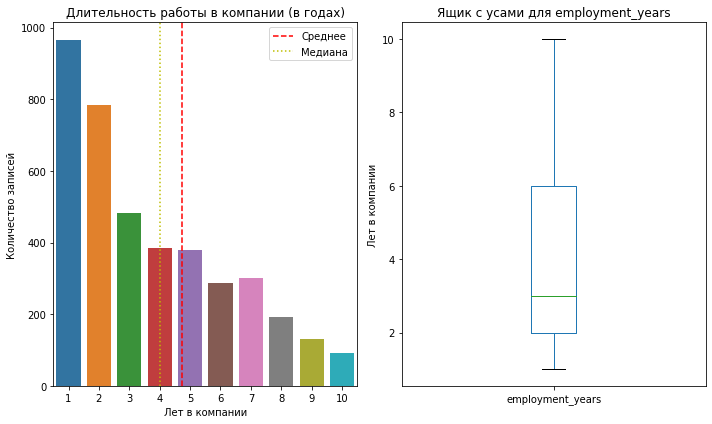

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

sns.countplot(x='employment_years', data=train_job_satisfaction_rate, ax=ax1)
ax1.set_title('Длительность работы в компании (в годах)')
ax1.set_xlabel('Лет в компании')
ax1.set_ylabel('Количество записей')

mean_value = train_job_satisfaction_rate['employment_years'].mean()
median_value = train_job_satisfaction_rate['employment_years'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

train_job_satisfaction_rate['employment_years'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами для employment_years')
ax2.set_ylabel('Лет в компании')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Тут у нас явная правосторонняя ассиметрия, вызванная большим количеством работников с малым стажем. Есть смысл логарифмировать данный показатель при машинном анализе (?).
</div>

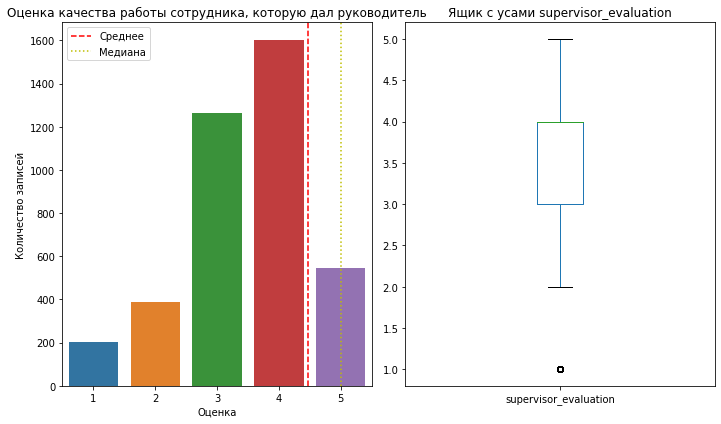

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

sns.countplot(x='supervisor_evaluation', data=train_job_satisfaction_rate, ax=ax1)
ax1.set_title('Оценка качества работы сотрудника, которую дал руководитель')
ax1.set_xlabel('Оценка')
ax1.set_ylabel('Количество записей')

mean_value = train_job_satisfaction_rate['supervisor_evaluation'].mean()
median_value = train_job_satisfaction_rate['supervisor_evaluation'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

train_job_satisfaction_rate['supervisor_evaluation'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами supervisor_evaluation')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    А тут распределение конкретно смещено в пользу высоких оценок, чтот делает низкие оценки (1-2) редкими / выбросами. Возможно, на них стоит обратить внимание (?).
</div>

In [45]:
display(train_job_satisfaction_rate[train_job_satisfaction_rate['supervisor_evaluation'] <= 1])

,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,job_satisfaction_rate
0,155278,sales,junior,medium,2,no,no,1,24000,0.58
18,848242,sales,middle,high,2,yes,no,1,50400,0.39
32,176144,hr,senior,high,3,no,no,1,72000,0.22
45,538347,technology,senior,high,3,no,no,1,84000,0.21
53,460328,technology,junior,high,1,no,no,1,37200,0.10
...,...,...,...,...,...,...,...,...,...,...
3877,947224,technology,junior,medium,3,no,no,1,30000,0.38
3949,157562,technology,middle,medium,3,no,no,1,49200,0.39
3972,134106,hr,middle,high,10,no,yes,1,57600,0.39
3988,806663,sales,middle,low,8,no,no,1,22800,0.39


<div style="background-color: white; color: olive;">
    Аж 198 строк с колами, вау... Это реальные колы, похоже.
</div>

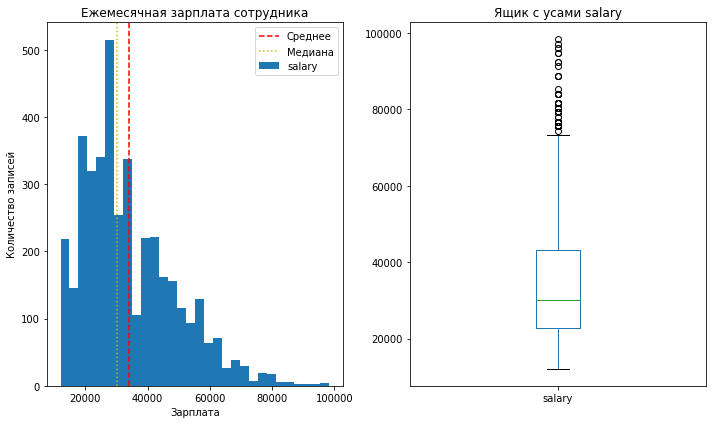

In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

train_job_satisfaction_rate['salary'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('Ежемесячная зарплата сотрудника')
ax1.set_xlabel('Зарплата')
ax1.set_ylabel('Количество записей')

mean_value = train_job_satisfaction_rate['salary'].mean()
median_value = train_job_satisfaction_rate['salary'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

train_job_satisfaction_rate['salary'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами salary')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Снова правосторонняя ассиметрия, о чём помимо глаз говорит среднее больше медианного. Имеются выбросы в зоне высоких зарплат. Возможно, на них стоит взглянуть (?).
</div>

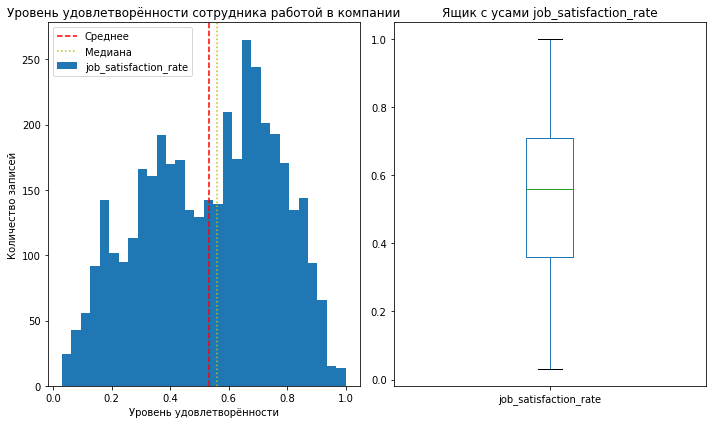

In [47]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

train_job_satisfaction_rate['job_satisfaction_rate'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('Уровень удовлетворённости сотрудника работой в компании')
ax1.set_xlabel('Уровень удовлетворённости')
ax1.set_ylabel('Количество записей')

mean_value = train_job_satisfaction_rate['job_satisfaction_rate'].mean()
median_value = train_job_satisfaction_rate['job_satisfaction_rate'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

train_job_satisfaction_rate['job_satisfaction_rate'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами job_satisfaction_rate')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    А вот это близко к нормальному симметричному распределению.
</div>

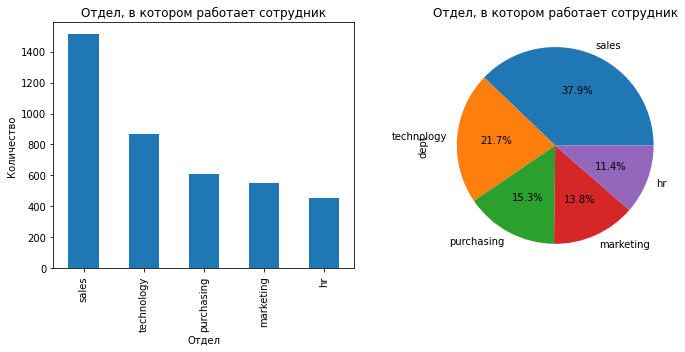

In [48]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_job_satisfaction_rate['dept'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Отдел, в котором работает сотрудник')
ax1.set_xlabel('Отдел')
ax1.set_ylabel('Количество')

train_job_satisfaction_rate['dept'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Отдел, в котором работает сотрудник')

plt.tight_layout()
plt.show()

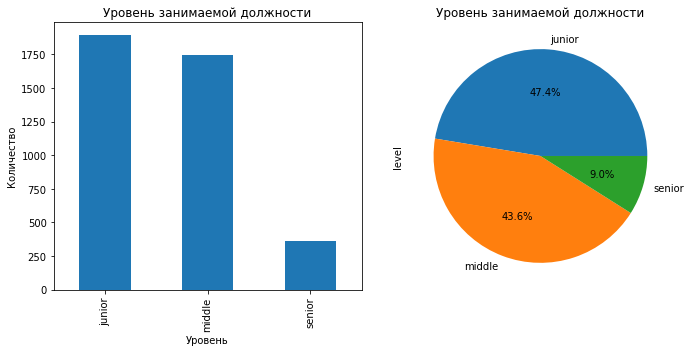

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_job_satisfaction_rate['level'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Уровень занимаемой должности')
ax1.set_xlabel('Уровень')
ax1.set_ylabel('Количество')

train_job_satisfaction_rate['level'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Уровень занимаемой должности')

plt.tight_layout()
plt.show()

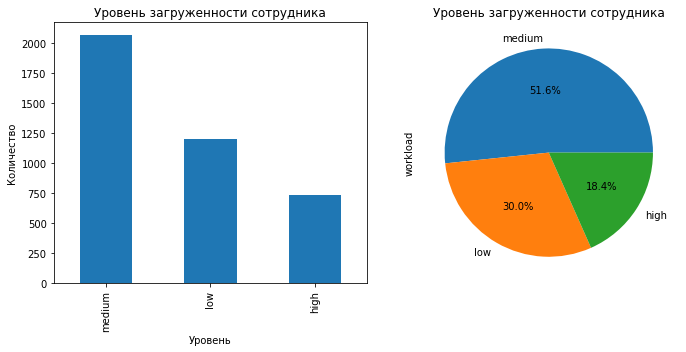

In [50]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_job_satisfaction_rate['workload'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Уровень загруженности сотрудника')
ax1.set_xlabel('Уровень')
ax1.set_ylabel('Количество')

train_job_satisfaction_rate['workload'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Уровень загруженности сотрудника')

plt.tight_layout()
plt.show()

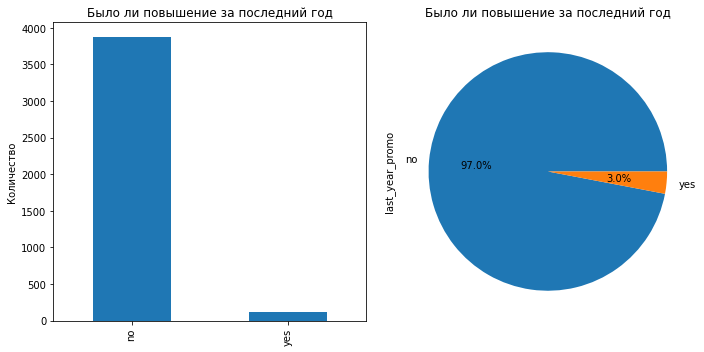

In [51]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_job_satisfaction_rate['last_year_promo'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Было ли повышение за последний год')
ax1.set_ylabel('Количество')

train_job_satisfaction_rate['last_year_promo'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Было ли повышение за последний год')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    А тут вот у нас явный дисбаланс классов. Мяу:(
</div>

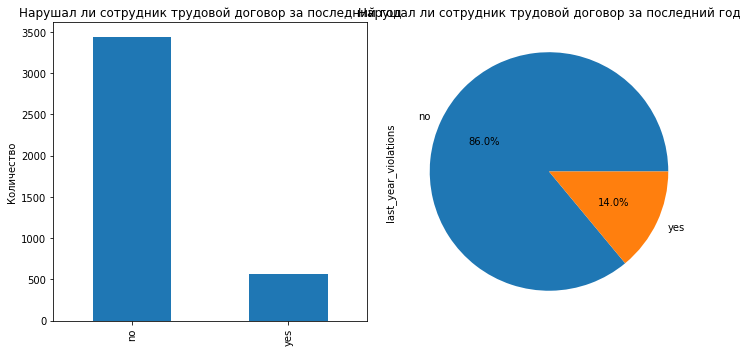

In [52]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_job_satisfaction_rate['last_year_violations'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Нарушал ли сотрудник трудовой договор за последний год')
ax1.set_ylabel('Количество')

train_job_satisfaction_rate['last_year_violations'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Нарушал ли сотрудник трудовой договор за последний год')

plt.tight_layout()
plt.show()

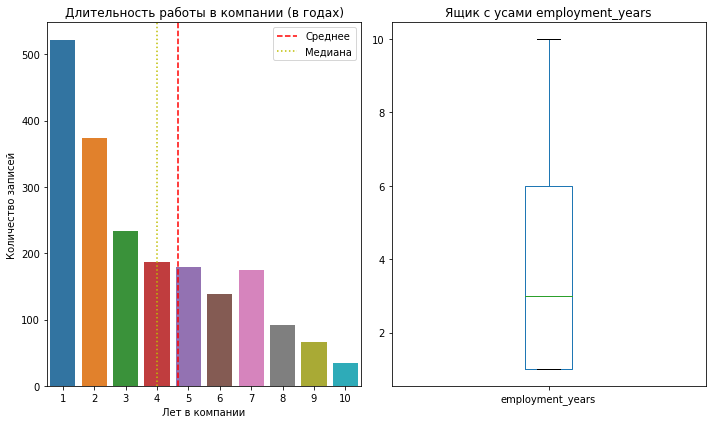

In [53]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

sns.countplot(x='employment_years', data=test_features, ax=ax1)
ax1.set_title('Длительность работы в компании (в годах)')
ax1.set_xlabel('Лет в компании')
ax1.set_ylabel('Количество записей')

mean_value = test_features['employment_years'].mean()
median_value = test_features['employment_years'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

test_features['employment_years'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами employment_years')

plt.tight_layout()
plt.show()

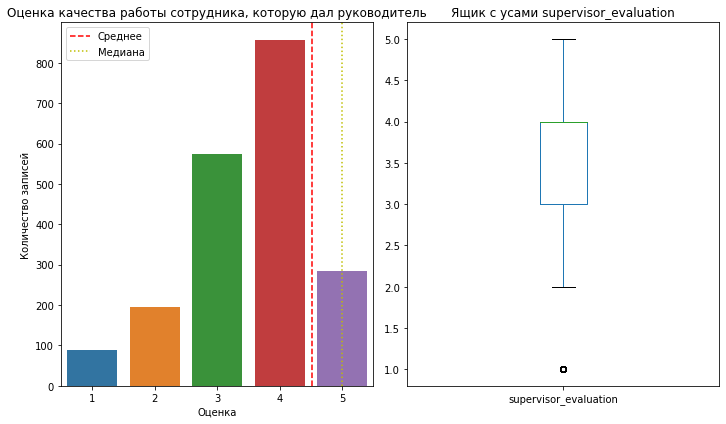

In [54]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

sns.countplot(x='supervisor_evaluation', data=test_features, ax=ax1)
ax1.set_title('Оценка качества работы сотрудника, которую дал руководитель')
ax1.set_xlabel('Оценка')
ax1.set_ylabel('Количество записей')

mean_value = test_features['supervisor_evaluation'].mean()
median_value = test_features['supervisor_evaluation'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

test_features['supervisor_evaluation'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами supervisor_evaluation')

plt.tight_layout()
plt.show()

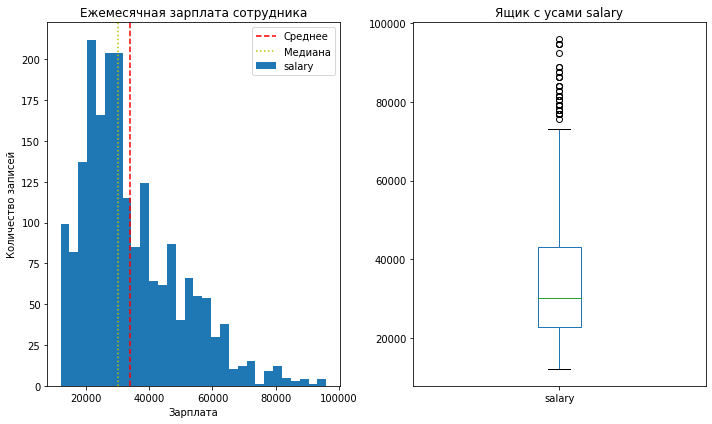

In [55]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

test_features['salary'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('Ежемесячная зарплата сотрудника')
ax1.set_xlabel('Зарплата')
ax1.set_ylabel('Количество записей')

mean_value = test_features['salary'].mean()
median_value = test_features['salary'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

test_features['salary'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами salary')

plt.tight_layout()
plt.show()

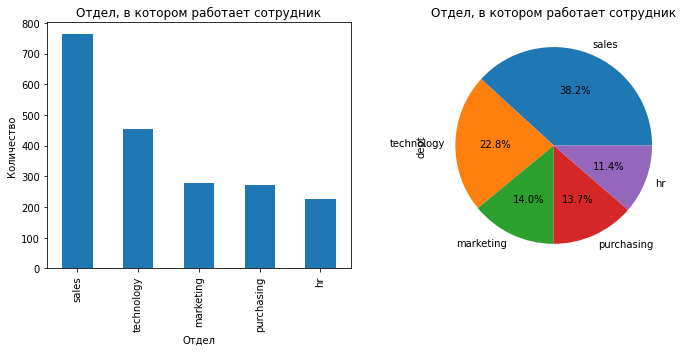

In [56]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

test_features['dept'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Отдел, в котором работает сотрудник')
ax1.set_xlabel('Отдел')
ax1.set_ylabel('Количество')

test_features['dept'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Отдел, в котором работает сотрудник')

plt.tight_layout()
plt.show()

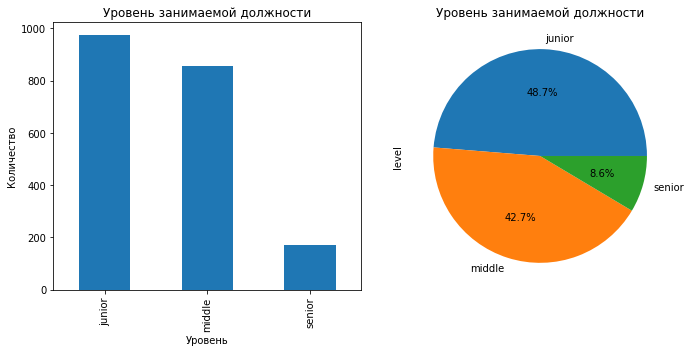

In [57]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

test_features['level'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Уровень занимаемой должности')
ax1.set_xlabel('Уровень')
ax1.set_ylabel('Количество')

test_features['level'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Уровень занимаемой должности')

plt.tight_layout()
plt.show()

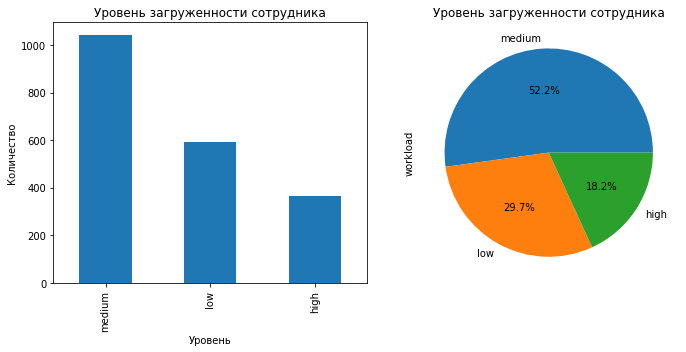

In [58]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

test_features['workload'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Уровень загруженности сотрудника')
ax1.set_xlabel('Уровень')
ax1.set_ylabel('Количество')

test_features['workload'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Уровень загруженности сотрудника')

plt.tight_layout()
plt.show()

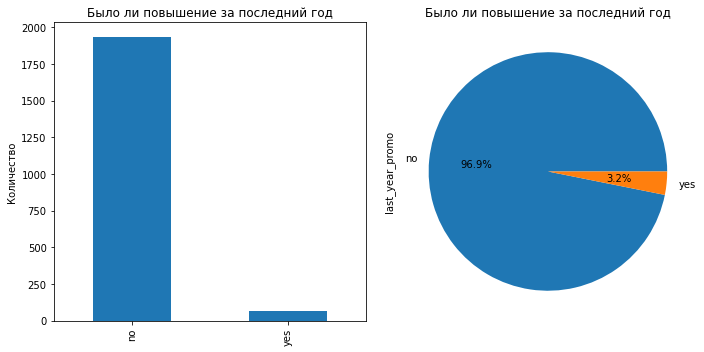

In [59]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

test_features['last_year_promo'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Было ли повышение за последний год')
ax1.set_ylabel('Количество')

test_features['last_year_promo'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Было ли повышение за последний год')

plt.tight_layout()
plt.show()

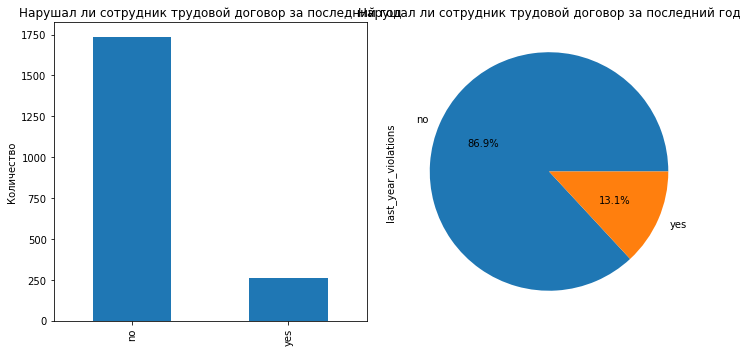

In [60]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

test_features['last_year_violations'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Нарушал ли сотрудник трудовой договор за последний год')
ax1.set_ylabel('Количество')

test_features['last_year_violations'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Нарушал ли сотрудник трудовой договор за последний год')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Приятно, что в тестовой выборке приблизительно такие же соотношения, что и в основной.
</div>

<div style="background-color: white; color: olive;">
    Пришло время соединить тестовые данные в одну таблицу.
</div>

## Объединение таблиц

In [61]:
test_data = test_features.merge(test_target_job_satisfaction_rate, how='left', on='id')

In [62]:
display(train_job_satisfaction_rate.head(10))
display(test_data.head(10))

,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,job_satisfaction_rate
0,155278,sales,junior,medium,2,no,no,1,24000,0.58
1,653870,hr,junior,high,2,no,no,5,38400,0.76
2,184592,sales,junior,low,1,no,no,2,12000,0.11
3,171431,technology,junior,low,4,no,no,2,18000,0.37
4,693419,hr,junior,medium,1,no,no,3,22800,0.20
5,405448,hr,middle,low,7,no,no,4,30000,0.78
6,857135,sales,senior,medium,9,no,no,3,56400,0.56
7,400657,purchasing,middle,high,9,no,no,3,52800,0.44
8,198846,hr,junior,low,1,no,no,2,13200,0.14
9,149797,technology,middle,high,6,no,no,3,54000,0.47


,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,job_satisfaction_rate
0,485046,marketing,junior,medium,2,no,no,5,28800,0.79
1,686555,hr,junior,medium,1,no,no,4,30000,0.72
2,467458,sales,middle,low,5,no,no,4,19200,0.64
3,418655,sales,middle,low,6,no,no,4,19200,0.60
4,789145,hr,middle,medium,5,no,no,5,40800,0.75
5,429973,purchasing,middle,medium,6,no,no,3,42000,0.67
6,850699,technology,junior,medium,3,no,no,3,26400,0.36
7,500791,sales,middle,high,9,no,no,4,49200,0.73
8,767867,marketing,middle,high,3,no,yes,4,62400,0.44
9,937235,sales,junior,medium,1,no,yes,3,26400,0.22


<div style="background-color: white; color: olive;">
    Теперь перед тем, как я перейду к корреляционному анализу, думаю, стоит поместить id в обоих датасетах в index, чтобы не смотреть корреляцию с id и не дропать id из столбцов машинного обучения в будущем.
</div>

In [63]:
train_job_satisfaction_rate = train_job_satisfaction_rate.set_index('id')
test_data = test_data.set_index('id')

## Корреляционный анализ данных

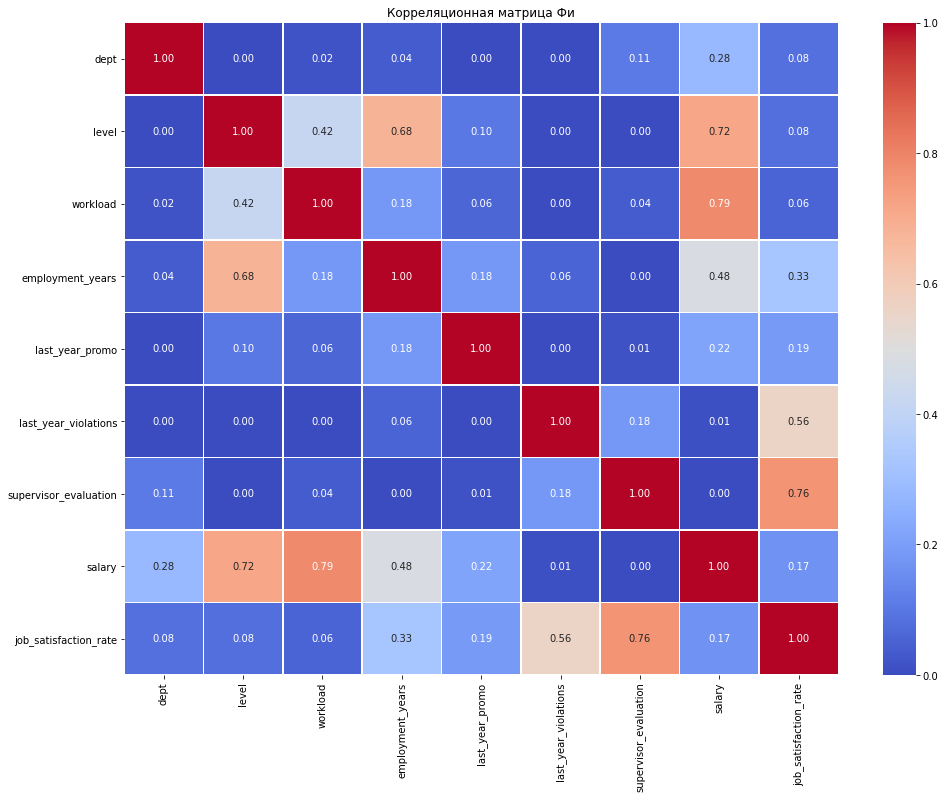

Пары признаков со значимой корреляцией:
employment_years и level: 0.68
salary и level: 0.72
salary и workload: 0.79
job_satisfaction_rate и supervisor_evaluation: 0.76


In [64]:
interval_cols = ['job_satisfaction_rate', 'salary']

# Вычисляем корреляционную матрицу Фи
phik_corr_matrix = train_job_satisfaction_rate.phik_matrix(interval_cols=interval_cols)

# Визуализация корреляционной матрицы
plt.figure(figsize=(16, 12))
sns.heatmap(phik_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Корреляционная матрица Фи')
plt.show()

# Анализ мультиколлинеарности
high_corr_pairs = []
for i in range(len(phik_corr_matrix.columns)):
    for j in range(i):
        if abs(phik_corr_matrix.iloc[i, j]) > 0.6:
            pair = (phik_corr_matrix.columns[i], phik_corr_matrix.columns[j], phik_corr_matrix.iloc[i, j])
            high_corr_pairs.append(pair)

print("Пары признаков со значимой корреляцией:")
for pair in high_corr_pairs:
    print(f"{pair[0]} и {pair[1]}: {pair[2]:.2f}")

<div style="background-color: white; color: olive;">
        Что можно сказать? Мультиколлинеарности я не вижу. Есть явные логически объяснимые корреляции: между годами работы и уровнем сотрудника, между уровнем сотрудника и его зарплатой, между зарплатой и рабочей нагрузкой, и (этого я не ожидал) оценкой качества работы сотрудника и его уровнем удовлетворённости.
</div>

## Использование пайплайнов

<div style="background-color: white; color: olive;">
        Разобьём наши данные на количественные и категориальные (тут же) для начала.
</div>

In [65]:
train_job_satisfaction_rate.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4000 entries, 155278 to 338347
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dept                   3994 non-null   object 
 1   level                  3996 non-null   object 
 2   workload               4000 non-null   object 
 3   employment_years       4000 non-null   int64  
 4   last_year_promo        4000 non-null   object 
 5   last_year_violations   4000 non-null   object 
 6   supervisor_evaluation  4000 non-null   int64  
 7   salary                 4000 non-null   int64  
 8   job_satisfaction_rate  4000 non-null   float64
dtypes: float64(1), int64(3), object(5)
memory usage: 312.5+ KB


In [67]:
# Разделяем категориальные признаки на упорядоченные и неупорядоченные
ordinal_features = ['level', 'workload']  # Упорядоченные категории
categorical_features_ohe = ['dept', 'last_year_promo', 'last_year_violations']  # Неупорядоченные категории

# Числовые признаки (без логарифмирования)
numerical_features = train_job_satisfaction_rate.drop(
    columns=['job_satisfaction_rate']
).select_dtypes(include=['int64', 'float64']).columns.tolist()

# Преобразуем количественные признаки
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # Заполнение пропусков
    ('scaler', StandardScaler())  # Стандартизация
])

# Преобразуем категориальные признаки с OneHotEncoder (для неупорядоченных признаков)
categorical_transformer_ohe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Заполнение пропусков
    ('encoder', OneHotEncoder(drop='first'))  # Убрали handle_unknown='ignore'
])

# Преобразуем категориальные признаки с OrdinalEncoder (для упорядоченных признаков)
categorical_transformer_oe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Заполнение пропусков
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan))
])

# Объединяем трансформации для числовых и категориальных признаков
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat_ohe', categorical_transformer_ohe, categorical_features_ohe),
        ('cat_oe', categorical_transformer_oe, ordinal_features)
    ]
)

def smape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return 100 / len(y_true) * np.sum(np.abs(y_pred - y_true) / ((np.abs(y_true) + np.abs(y_pred)) / 2))

smape_scorer = make_scorer(smape, greater_is_better=False)

scoring = {
    'smape': smape_scorer
}

# Используем весь датасет train_job_satisfaction_rate как обучающую выборку
X = train_job_satisfaction_rate.drop(columns=['job_satisfaction_rate'])
y = train_job_satisfaction_rate['job_satisfaction_rate']

# Пайплайны только для моделей на основе деревьев
pipeline_dt = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(random_state=42))
])

pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])

pipeline_gb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(random_state=42))
])

# Гиперпараметры для моделей
param_grid_dt = {
    'regressor__max_depth': [3, 5, 7, 10],
    'regressor__min_samples_split': [2, 5, 10]
}

param_grid_rf = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [None, 10, 20],
    'regressor__min_samples_split': [2, 5]
}

param_grid_gb = {
    'regressor__n_estimators': [100, 200],
    'regressor__learning_rate': [0.01, 0.1, 0.2],
    'regressor__max_depth': [3, 5, 7]
}

# Подбор гиперпараметров с метрикой SMAPE
grid_dt = GridSearchCV(pipeline_dt, param_grid_dt, cv=5, scoring=scoring, refit='smape')
grid_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=5, scoring=scoring, refit='smape')
grid_gb = GridSearchCV(pipeline_gb, param_grid_gb, cv=5, scoring=scoring, refit='smape')

# Обучение моделей на всей обучающей выборке
grid_dt.fit(X, y)
grid_rf.fit(X, y)
grid_gb.fit(X, y)

# Определяем лучшую модель по значению best_score_
best_models = {
    'Decision Tree': (grid_dt.best_score_, grid_dt.best_estimator_),
    'Random Forest': (grid_rf.best_score_, grid_rf.best_estimator_),
    'Gradient Boosting': (grid_gb.best_score_, grid_gb.best_estimator_)
}

# Находим модель с наименьшим best_score_ (так как SMAPE нужно минимизировать)
best_model_name, (best_score, best_estimator) = min(best_models.items(), key=lambda x: x[1][0])
print(f"Лучшая модель: {best_model_name} с best_score (SMAPE): {-best_score}")

# Выводим параметры лучшей модели
print('Лучшая модель и её параметры:\n\n', best_estimator)

Лучшая модель: Decision Tree с best_score (SMAPE): 15.690171239995115
Лучшая модель и её параметры:

 Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['employment_years',
                                                   'supervisor_evaluation',
                                                   'salary']),
                                                 ('cat_ohe',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
     

<div style="background-color: white; color: olive;">
        Т.к. мне надо предсказывать удовлетворённость (которая небинарная), то это задача регрессии, соответственно, метрики roc_auc, f1, precision, recall не подходят, остаётся SMAPE.
</div>

## Определяем лучшую модель

In [75]:
# Определяем лучшую модель по значению best_score_
best_models = {
    'Decision Tree': (grid_dt.best_score_, grid_dt.best_estimator_),
    'Random Forest': (grid_rf.best_score_, grid_rf.best_estimator_),
    'Gradient Boosting': (grid_gb.best_score_, grid_gb.best_estimator_)
}

# Находим модель с наименьшим best_score_ (так как SMAPE нужно минимизировать)
best_model_name_regression, (best_score_regression, best_estimator_regression) = min(best_models.items(), key=lambda x: x[1][0])
print(f"Лучшая модель регрессии: {best_model_name_regression} с best_score (SMAPE): {-best_score_regression}")

Лучшая модель регрессии: Decision Tree с best_score (SMAPE): 15.690171239995115


In [76]:
# Сохраняем реальные значения job_satisfaction_rate для сравнения
y_test_real = test_data['job_satisfaction_rate']

# Удаляем job_satisfaction_rate из test_data
X_test_data = test_data.drop(columns=['job_satisfaction_rate'])

# Убедимся, что порядок столбцов в X_test_data совпадает с порядком в X (обучающей выборке)
X_test_data = X_test_data[X.columns]

# Предсказываем значения job_satisfaction_rate для test_data
test_predictions = best_estimator_regression.predict(X_test_data)

# Добавляем предсказания в test_data
test_data['predicted_job_satisfaction_rate'] = test_predictions

# Рассчитываем SMAPE для предсказаний на test_data
test_smape = smape(y_test_real, test_data['predicted_job_satisfaction_rate'])
print(f"SMAPE на тестовом наборе test_data: {test_smape}")

# Показываем первые несколько строк с предсказаниями и реальными значениями
display(test_data[['job_satisfaction_rate', 'predicted_job_satisfaction_rate']].head(20))

SMAPE на тестовом наборе test_data: 14.757342647376754


,job_satisfaction_rate,predicted_job_satisfaction_rate
id,,
485046,0.79,0.833855
686555,0.72,0.673434
467458,0.64,0.664074
418655,0.60,0.664074
789145,0.75,0.807181
429973,0.67,0.489588
850699,0.36,0.386538
500791,0.73,0.765798
767867,0.44,0.360000


<div style="background-color: white; color: olive;">
        Предсказания относительно близки, но недостаточно. Тем не менее, я не совсем знаю, что с этим делать, ибо попытался выше несколько идей осуществить, как итог -- всё сломал и долго восстанавлливал (быстрее было бы с нуля всё сделать по новой). Перейду пока что ко второй задаче!
    Что-то заинтриговала меня отрицательная удовлетворённость в предсказаниях, надо будет и об этом подумать.
</div>

## Промежуточные выводы 1

<div style="background-color: black; color: #FFA500;">
    Итак, у нас наиболее эффективным оказалось дерево решений (Decision Tree), это значит:
    <br/>
    <br/>
    1) Зависимость между признаками не является линейной;
    <br/>
    2) Деревья хорошо работают с дискретными признаками, значит в нашем наборе данных дискретные признаки являются весьма весомыми для предсказания.
</div>

<div style="background-color: white; color: olive;">
        Перейдём ко второму заданию, теперь нам необходимо предсказывать увольнение сотрудника из компании. Тестовая выборка остаётся неизменной, а тренировочную выборку и целевую переменную надо подгрузить.
</div>

## Загрузка данных 2

In [77]:
url_4 = 'https://drive.google.com/uc?export=download&id=1zmS6GW9c5zTM9QhmlXr8ifi1LaeeOaMU'
response_4 = requests.get(url_4)
data_4 = io.StringIO(response_4.text)
train_quit = pd.read_csv(data_4)

In [78]:
url_5 = 'https://drive.google.com/uc?export=download&id=1oYneNvl_EcaZqXTRqDTs1cpV9LVX0tMr'
response_5 = requests.get(url_5)
data_5 = io.StringIO(response_5.text)
test_target_quit = pd.read_csv(data_5)

In [79]:
display(train_quit)

,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,quit
0,723290,sales,middle,high,2,no,no,4,54000,no
1,814010,sales,junior,medium,2,no,no,4,27600,no
2,155091,purchasing,middle,medium,5,no,no,1,37200,no
3,257132,sales,junior,medium,2,no,yes,3,24000,yes
4,910140,marketing,junior,medium,2,no,no,5,25200,no
...,...,...,...,...,...,...,...,...,...,...
3995,588809,sales,junior,medium,4,no,no,3,26400,no
3996,672059,sales,middle,high,9,no,no,4,52800,no
3997,536432,purchasing,junior,low,2,no,yes,4,12000,yes
3998,692133,purchasing,middle,medium,2,no,no,4,33600,no


In [80]:
display(test_target_quit)

,id,quit
0,999029,yes
1,372846,no
2,726767,no
3,490105,no
4,416898,yes
...,...,...
1995,836109,yes
1996,180999,yes
1997,746018,no
1998,247658,no


## Предобработка данных 2

In [81]:
train_quit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   id                     4000 non-null   int64 
 1   dept                   4000 non-null   object
 2   level                  4000 non-null   object
 3   workload               4000 non-null   object
 4   employment_years       4000 non-null   int64 
 5   last_year_promo        4000 non-null   object
 6   last_year_violations   4000 non-null   object
 7   supervisor_evaluation  4000 non-null   int64 
 8   salary                 4000 non-null   int64 
 9   quit                   4000 non-null   object
dtypes: int64(4), object(6)
memory usage: 312.6+ KB


In [82]:
test_target_quit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   quit    2000 non-null   object
dtypes: int64(1), object(1)
memory usage: 31.4+ KB


In [83]:
display(train_quit['dept'].unique())

array(['sales', 'purchasing', 'marketing', 'technology', 'hr'],
      dtype=object)

In [84]:
display(train_quit['level'].unique())

array(['middle', 'junior', 'sinior'], dtype=object)

In [85]:
train_quit['level'] = train_quit['level'].replace('sinior', 'senior')

In [86]:
display(train_quit['workload'].unique())

array(['high', 'medium', 'low'], dtype=object)

In [87]:
display(train_quit['last_year_promo'].unique())

array(['no', 'yes'], dtype=object)

In [88]:
display(train_quit['last_year_violations'].unique())

array(['no', 'yes'], dtype=object)

In [89]:
display(train_quit['quit'].unique())

array(['no', 'yes'], dtype=object)

In [90]:
display(test_target_quit['quit'].unique())

array(['yes', 'no'], dtype=object)

<div style="background-color: white; color: olive;">
    Вроде бы, тут всё в полном порядке, разве что sinior я вновь заменил на senior, ибо это чёртов я...
</div>

In [91]:
display(train_quit.isnull().sum())
display(test_target_quit.isnull().sum())

id                       0
dept                     0
level                    0
workload                 0
employment_years         0
last_year_promo          0
last_year_violations     0
supervisor_evaluation    0
salary                   0
quit                     0
dtype: int64

id      0
quit    0
dtype: int64

In [92]:
display(train_quit.duplicated().sum())
display(test_target_quit.duplicated().sum())

0

0

## Исследовательский анализ данных 2

<div style="background-color: white; color: olive;">
    На этом этапе перенесу id в индекс, чтобы и потом не путаться, и чтобы нормально соединить признаки, где id уже убраны в индекс, с целевой переменной.
</div>

In [93]:
train_quit = train_quit.set_index('id')
#test_target_quit = test_target_quit.set_index('id')

<div style="background-color: white; color: olive;">
    Теперь мне интересно, насколько датасет train_quit похож на train_job_satisfaction_rate, который мы уже анализировали несного выше в данном проекте.
</div>

In [94]:
display(train_quit.head(15))
display(train_job_satisfaction_rate.head(15))

,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,quit
id,,,,,,,,,
723290,sales,middle,high,2,no,no,4,54000,no
814010,sales,junior,medium,2,no,no,4,27600,no
155091,purchasing,middle,medium,5,no,no,1,37200,no
257132,sales,junior,medium,2,no,yes,3,24000,yes
910140,marketing,junior,medium,2,no,no,5,25200,no
699916,sales,junior,low,1,no,yes,3,18000,yes
417070,technology,middle,medium,8,no,no,2,44400,no
165489,sales,middle,low,4,no,no,5,19200,no
996399,marketing,middle,low,7,no,no,4,25200,no


,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,job_satisfaction_rate
id,,,,,,,,,
155278,sales,junior,medium,2,no,no,1,24000,0.58
653870,hr,junior,high,2,no,no,5,38400,0.76
184592,sales,junior,low,1,no,no,2,12000,0.11
171431,technology,junior,low,4,no,no,2,18000,0.37
693419,hr,junior,medium,1,no,no,3,22800,0.20
405448,hr,middle,low,7,no,no,4,30000,0.78
857135,sales,senior,medium,9,no,no,3,56400,0.56
400657,purchasing,middle,high,9,no,no,3,52800,0.44
198846,hr,junior,low,1,no,no,2,13200,0.14


In [95]:
pure_train_job_satisfaction_rate = train_job_satisfaction_rate.drop(
    columns=['job_satisfaction_rate']
)

In [96]:
pure_train_quit = train_quit.drop(
    columns=['quit']
)

In [97]:
if pure_train_job_satisfaction_rate.index.equals(pure_train_quit.index):
    print("Индексы полностью совпадают.")
else:
    print("Индексы не совпадают.")

    # Выведем индексы, которые есть в одном датафрейме, но отсутствуют в другом
    idx_in_first_not_in_second = pure_train_job_satisfaction_rate.index.difference(pure_train_quit.index)
    idx_in_second_not_in_first = pure_train_quit.index.difference(pure_train_job_satisfaction_rate.index)

    if not idx_in_first_not_in_second.empty:
        print("\nИндексы, которые есть в pure_train_job_satisfaction_rate, но отсутствуют в pure_train_quit:")
        print(idx_in_first_not_in_second.tolist())

    if not idx_in_second_not_in_first.empty:
        print("\nИндексы, которые есть в pure_train_quit, но отсутствуют в pure_train_job_satisfaction_rate:")
        print(idx_in_second_not_in_first.tolist())

Индексы не совпадают.

Индексы, которые есть в pure_train_job_satisfaction_rate, но отсутствуют в pure_train_quit:
[100954, 101057, 101074, 101081, 101129, 101159, 101249, 101334, 101661, 101890, 102068, 102464, 102496, 103035, 103343, 103449, 103565, 103838, 104245, 104297, 104519, 104636, 105082, 105199, 105776, 105921, 106020, 106077, 106320, 106442, 106537, 106754, 107482, 107782, 108060, 108126, 108289, 108560, 108962, 109161, 109353, 109612, 109804, 110710, 111053, 111346, 111941, 112348, 112987, 113520, 113614, 113849, 113956, 114519, 114587, 114675, 114966, 115165, 115447, 115761, 115943, 116628, 116933, 117034, 117180, 117482, 117865, 117952, 118705, 119037, 119097, 119172, 119287, 119382, 119981, 120057, 120110, 120658, 121506, 121707, 121773, 122260, 122287, 122760, 122833, 123373, 123388, 123838, 123843, 124306, 124896, 124949, 124975, 124982, 125059, 125162, 125326, 125347, 125547, 125644, 125699, 125735, 125737, 125839, 125976, 126257, 126397, 126422, 127116, 127632, 1283

<div style="background-color: white; color: olive;">
    У нас не совпадают индексы. Посмею предположить, что датасеты для обучения не являются абсолютно идентичными. Так что сперва проанализируем протсо столбцы нового датасета!
</div>

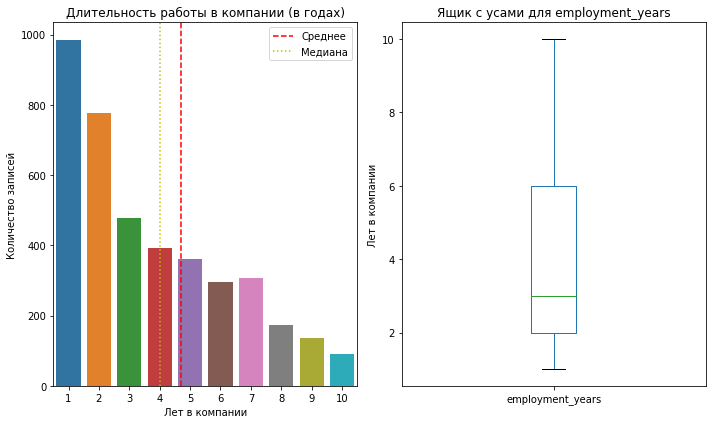

In [98]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

sns.countplot(x='employment_years', data=train_quit, ax=ax1)
ax1.set_title('Длительность работы в компании (в годах)')
ax1.set_xlabel('Лет в компании')
ax1.set_ylabel('Количество записей')

mean_value = train_quit['employment_years'].mean()
median_value = train_quit['employment_years'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

train_quit['employment_years'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами для employment_years')
ax2.set_ylabel('Лет в компании')

plt.tight_layout()
plt.show()

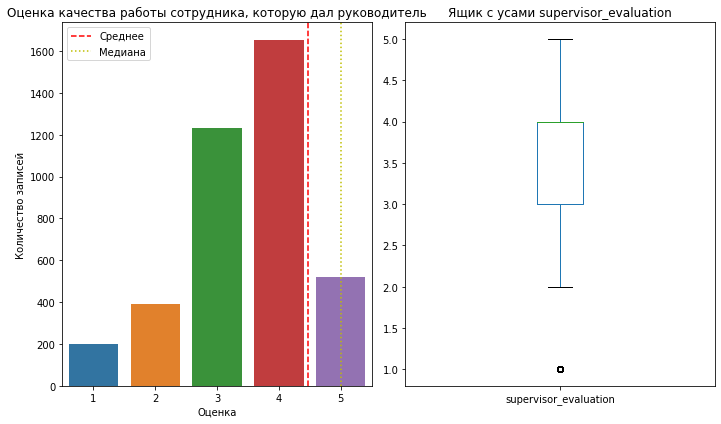

In [99]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

sns.countplot(x='supervisor_evaluation', data=train_quit, ax=ax1)
ax1.set_title('Оценка качества работы сотрудника, которую дал руководитель')
ax1.set_xlabel('Оценка')
ax1.set_ylabel('Количество записей')

mean_value = train_quit['supervisor_evaluation'].mean()
median_value = train_quit['supervisor_evaluation'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

train_quit['supervisor_evaluation'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами supervisor_evaluation')

plt.tight_layout()
plt.show()

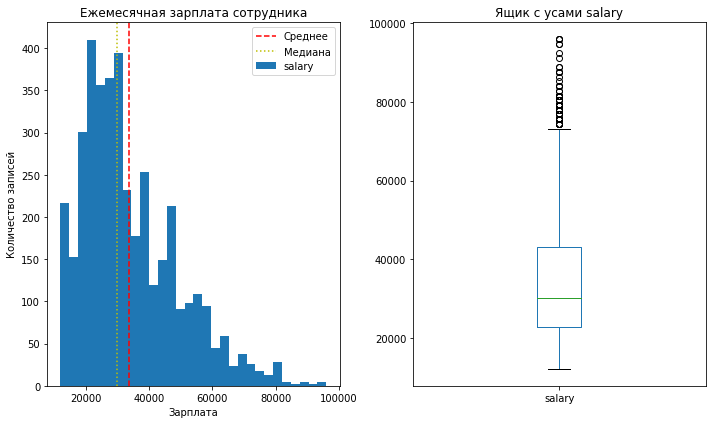

In [100]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

train_quit['salary'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('Ежемесячная зарплата сотрудника')
ax1.set_xlabel('Зарплата')
ax1.set_ylabel('Количество записей')

mean_value = train_quit['salary'].mean()
median_value = train_quit['salary'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

train_quit['salary'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами salary')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    И снова та же история: да, у нас есть люди с оценкой супервайзера в единицу, но ничто не мешает ставить единицу, и это выглядит вполне обоснованное. Да, есть люди с зарплатами сильно выше медианных, но мы и это рассматривали выше: нет оснований считать эти данные нереалистичными. К слову, у нас опять ассиметричные немного графики, стоит задуматься о логарифмировании признаков!
</div>

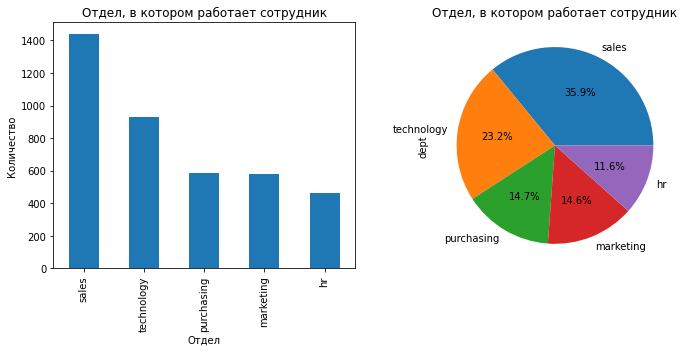

In [101]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_quit['dept'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Отдел, в котором работает сотрудник')
ax1.set_xlabel('Отдел')
ax1.set_ylabel('Количество')

train_quit['dept'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Отдел, в котором работает сотрудник')

plt.tight_layout()
plt.show()

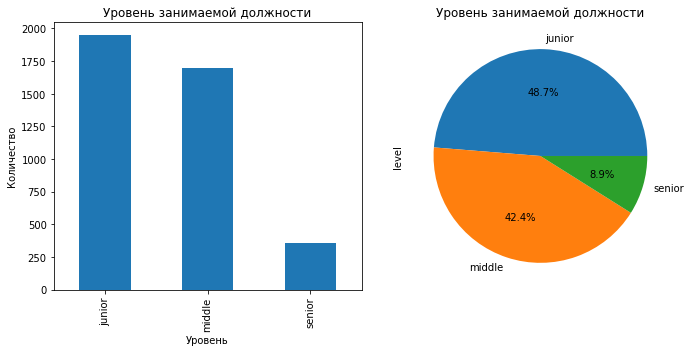

In [102]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_quit['level'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Уровень занимаемой должности')
ax1.set_xlabel('Уровень')
ax1.set_ylabel('Количество')

train_quit['level'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Уровень занимаемой должности')

plt.tight_layout()
plt.show()

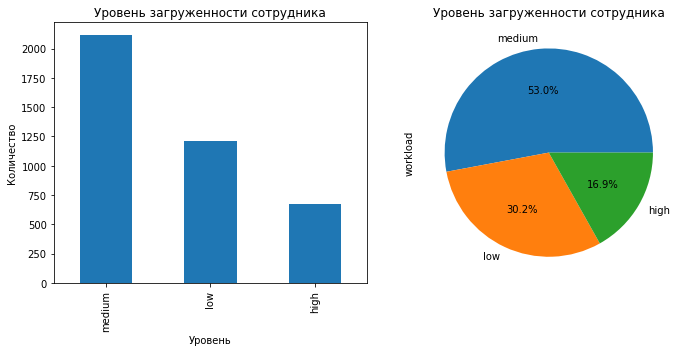

In [103]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_quit['workload'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Уровень загруженности сотрудника')
ax1.set_xlabel('Уровень')
ax1.set_ylabel('Количество')

train_quit['workload'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Уровень загруженности сотрудника')

plt.tight_layout()
plt.show()

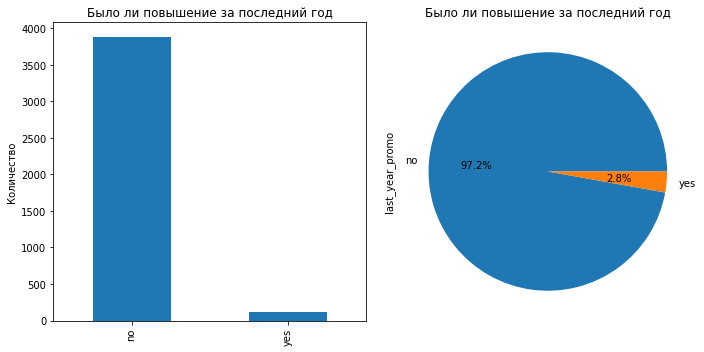

In [104]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_quit['last_year_promo'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Было ли повышение за последний год')
ax1.set_ylabel('Количество')

train_quit['last_year_promo'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Было ли повышение за последний год')

plt.tight_layout()
plt.show()

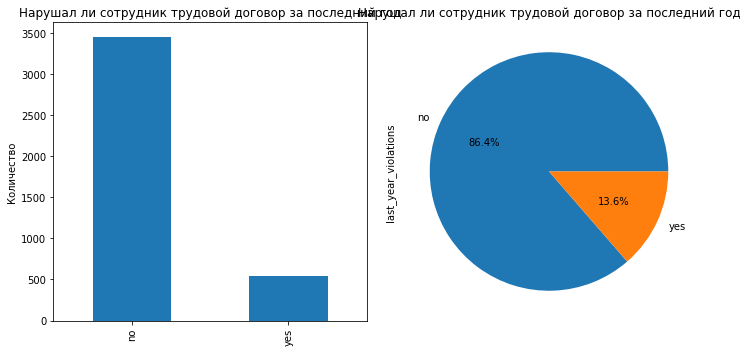

In [105]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_quit['last_year_violations'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Нарушал ли сотрудник трудовой договор за последний год')
ax1.set_ylabel('Количество')

train_quit['last_year_violations'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Нарушал ли сотрудник трудовой договор за последний год')

plt.tight_layout()
plt.show()

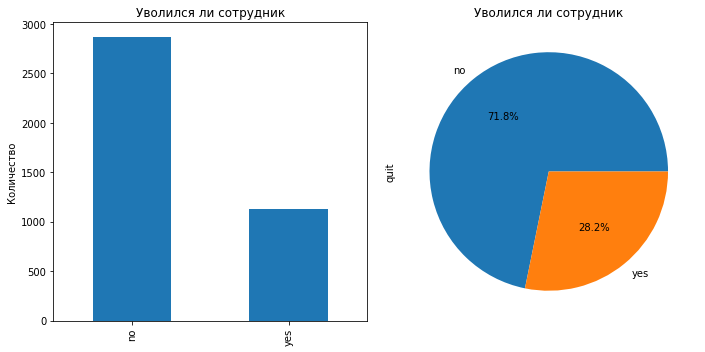

In [106]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

train_quit['quit'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Уволился ли сотрудник')
ax1.set_ylabel('Количество')

train_quit['quit'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Уволился ли сотрудник')

plt.tight_layout()
plt.show()

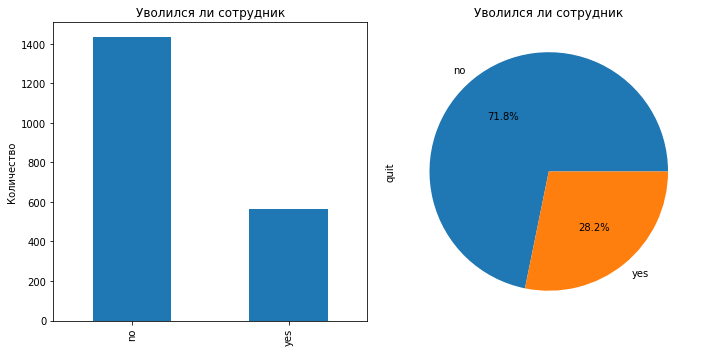

In [107]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

test_target_quit['quit'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Уволился ли сотрудник')
ax1.set_ylabel('Количество')

test_target_quit['quit'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Уволился ли сотрудник')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Тут у нас аналогичные проблемы: жёсткий дисбаланс признаков 'last_year_promo', 'last_year_violations'. Очень мало senior относительно других уровней специалистов.
</div>

<div style="background-color: white; color: olive;">
    Перед тем, как говорить о дальнейшем анализе данных и корреляционном анализе, добавим сюда 'job_satisfaction_rate'.
</div>

In [108]:
# Объединяем все признаки, которые использовались в обучении
all_features = numerical_features + categorical_features_ohe + ordinal_features

# Выбираем только те признаки, которые есть в train_quit, и удаляем 'quit'
X_quit = train_quit[all_features].drop(columns=['quit'], errors='ignore')

# Убедимся, что порядок столбцов совпадает с порядком в X (обучающей выборке)
X_quit = X_quit[X.columns]

# Предсказываем значения job_satisfaction_rate
quit_predictions = best_estimator_regression.predict(X_quit)

# Добавляем предсказания в train_quit
train_quit['predicted_job_satisfaction_rate'] = quit_predictions

# Показываем первые 10 строк
display(train_quit.head(10))

,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,quit,predicted_job_satisfaction_rate
id,,,,,,,,,,
723290,sales,middle,high,2,no,no,4,54000,no,0.601169
814010,sales,junior,medium,2,no,no,4,27600,no,0.833855
155091,purchasing,middle,medium,5,no,no,1,37200,no,0.433793
257132,sales,junior,medium,2,no,yes,3,24000,yes,0.334444
910140,marketing,junior,medium,2,no,no,5,25200,no,0.794667
699916,sales,junior,low,1,no,yes,3,18000,yes,0.111667
417070,technology,middle,medium,8,no,no,2,44400,no,0.433793
165489,sales,middle,low,4,no,no,5,19200,no,0.463333
996399,marketing,middle,low,7,no,no,4,25200,no,0.813529


<div style="background-color: white; color: olive;">
    Сейчас взглянем впервые на то, как решение об увольнении соотносится со средними и медианными показателями предсказанной удовлетворённости сотрудника.
</div>

In [109]:
grouped_quit = train_quit.groupby('quit')['predicted_job_satisfaction_rate'].agg(['mean', 'median'])
print("Средние и медианные значения predicted_job_satisfaction_rate для уволившихся / не уволившихся:")
display(grouped_quit)


print("\nОписательная статистика для не уволившихся (удовлетворённость):")
display(train_quit[train_quit['quit'] == 'no']['predicted_job_satisfaction_rate'].describe())
print("\nОписательная статистика для уволившихся (удовлетворённость):")
display(train_quit[train_quit['quit'] == 'yes']['predicted_job_satisfaction_rate'].describe())

Средние и медианные значения predicted_job_satisfaction_rate для уволившихся / не уволившихся:


,mean,median
quit,,
no,0.591344,0.645000
yes,0.400637,0.362857



Описательная статистика для не уволившихся (удовлетворённость):


count    2872.000000
mean        0.591344
std         0.199669
min         0.030000
25%         0.441736
50%         0.645000
75%         0.765798
max         0.995000
Name: predicted_job_satisfaction_rate, dtype: float64


Описательная статистика для уволившихся (удовлетворённость):


count    1128.000000
mean        0.400637
std         0.188166
min         0.060000
25%         0.246667
50%         0.362857
75%         0.518000
max         0.850000
Name: predicted_job_satisfaction_rate, dtype: float64

<div style="background-color: white; color: olive;">
    Конечно, показатели далеко не идеальные. Первоочерёдно потому, что не очень хорошо рабюотает модель предсказаний для 'job_satisfaction_rate'.
<br/>
    <br/>
    Тем не менее, можно заметить, что как медианные, так и средние показатели удовлетворённости рабочим процессом, выше у тех, кто решил не увольняться. Соответственно, гипотеза об увольнении как следствии неудовлетворённости не лишена оснований.
</div>

In [110]:
print("\nОписательная статистика для не уволившихся (отдел):")
display(train_quit[train_quit['quit'] == 'no']['dept'].describe())
print("\nОписательная статистика для уволившихся (отдел):")
display(train_quit[train_quit['quit'] == 'yes']['dept'].describe())


Описательная статистика для не уволившихся (отдел):


count      2872
unique        5
top       sales
freq       1031
Name: dept, dtype: object


Описательная статистика для уволившихся (отдел):


count      1128
unique        5
top       sales
freq        407
Name: dept, dtype: object

In [111]:
total_by_dept = train_quit.groupby('dept').size()
quit_by_dept = train_quit[train_quit['quit'] == 'yes'].groupby('dept').size()

quit_percentage_by_dept = (quit_by_dept / total_by_dept) * 100

print("Процент уволившихся сотрудников в каждом отделе:")
display(quit_percentage_by_dept)

Процент уволившихся сотрудников в каждом отделе:


dept
hr            25.000000
marketing     28.006873
purchasing    28.231293
sales         28.303199
technology    29.741379
dtype: float64

In [112]:
print("\nОписательная статистика для не уволившихся (зарплата):")
display(train_quit[train_quit['quit'] == 'no']['salary'].describe())
print("\nОписательная статистика для уволившихся (зарплата):")
display(train_quit[train_quit['quit'] == 'yes']['salary'].describe())


Описательная статистика для не уволившихся (зарплата):


count     2872.000000
mean     37702.228412
std      15218.977339
min      12000.000000
25%      25200.000000
50%      34800.000000
75%      46800.000000
max      96000.000000
Name: salary, dtype: float64


Описательная статистика для уволившихся (зарплата):


count     1128.000000
mean     23885.106383
std       9351.599505
min      12000.000000
25%      16800.000000
50%      22800.000000
75%      27600.000000
max      79200.000000
Name: salary, dtype: float64

<div style="background-color: white; color: olive;">
    Что ещё можно сказать об уволившихся?
<br/>
    <br/>
    В среднем по больнице у уволившихся значительно меньше средние и медианные показатели уровня зарплат.
<br/>
    <br/>
    Кроме того, как большинство уволившихся, так и большинство оставшихся сотрудников принадлежат департаменту sales. Скорее всего это связано с тем, что это наиболее крупный по контингенту отдел. Если же считать в процентах от человеческого номинала отделов, то наиболее волатильным является отдел technology.
</div>

<div style="background-color: white; color: olive;">
    Для начала взглянем на среднюю удовлетворённость по отделам.
</div>

In [113]:
mean_satisfaction_by_dept = train_quit.groupby('dept')['predicted_job_satisfaction_rate'].mean().sort_values(ascending=False)
print("\nСредняя удовлетворённость по отделам:")
display(mean_satisfaction_by_dept)


Средняя удовлетворённость по отделам:


dept
marketing     0.555592
technology    0.541908
sales         0.537875
hr            0.531583
purchasing    0.516828
Name: predicted_job_satisfaction_rate, dtype: float64

<div style="background-color: white; color: olive;">
    Теперь взглянем на увольнения по уровню загруженности.
</div>

In [114]:
total_by_workload = train_quit.groupby('workload').size()
quit_by_workload = train_quit[train_quit['quit'] == 'yes'].groupby('workload').size()
quit_percentage_by_workload = (quit_by_workload / total_by_workload) * 100
print("\nПроцент уволившихся сотрудников по уровню загруженности:")
display(quit_percentage_by_workload)


Процент уволившихся сотрудников по уровню загруженности:


workload
high      17.952522
low       42.963576
medium    23.040604
dtype: float64

<div style="background-color: white; color: olive;">
    И мельком посмотрим на уровень удовлетворённости сотрудников тоже по градациям загруженности.
</div>

In [115]:
mean_satisfaction_by_workload = train_quit.groupby('workload')['predicted_job_satisfaction_rate'].mean().sort_values(ascending=False)
print("\nСредняя удовлетворённость по уровню загруженности:")
display(mean_satisfaction_by_workload)


Средняя удовлетворённость по уровню загруженности:


workload
high      0.553255
medium    0.537057
low       0.529700
Name: predicted_job_satisfaction_rate, dtype: float64

<div style="background-color: white; color: olive;">
    Визуализирую процент уволившихся сотрудников по отделам (я его уже выводил сверху, но думаю, что так будет нагляднее).
</div>

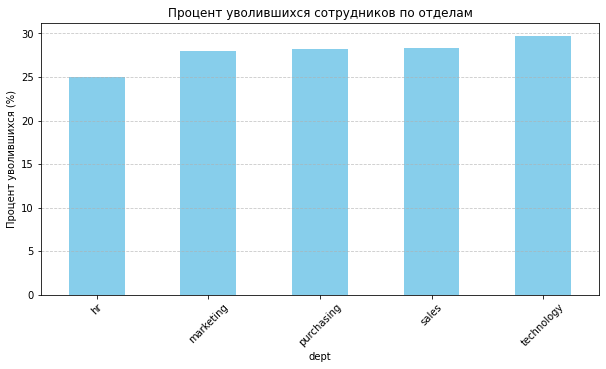

In [116]:
dept_order = ['hr', 'marketing', 'purchasing', 'sales', 'technology']

plt.figure(figsize=(10, 5))
quit_percentage_by_dept.reindex(dept_order).plot(kind='bar', color='skyblue')
plt.title('Процент уволившихся сотрудников по отделам')
plt.ylabel('Процент уволившихся (%)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

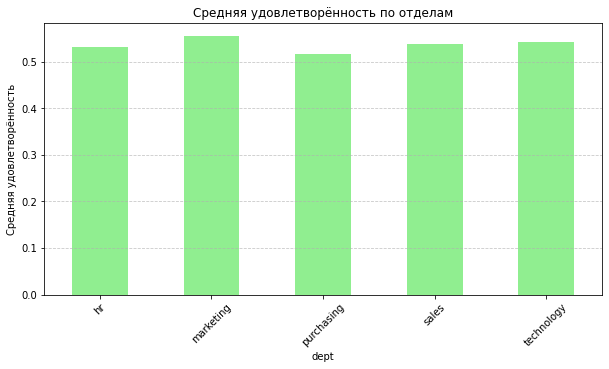

In [117]:
plt.figure(figsize=(10, 5))
mean_satisfaction_by_dept.reindex(dept_order).plot(kind='bar', color='lightgreen')
plt.title('Средняя удовлетворённость по отделам')
plt.ylabel('Средняя удовлетворённость')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

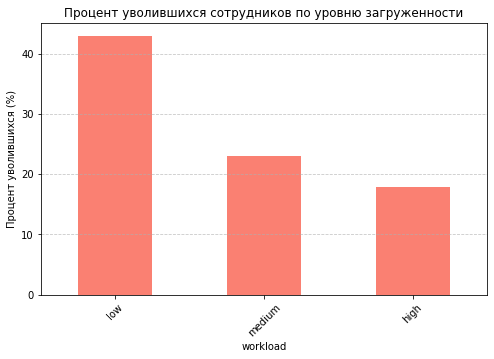

In [118]:
workload_order = ['low', 'medium', 'high']

plt.figure(figsize=(8, 5))
quit_percentage_by_workload.reindex(workload_order).plot(kind='bar', color='salmon')
plt.title('Процент уволившихся сотрудников по уровню загруженности')
plt.ylabel('Процент уволившихся (%)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

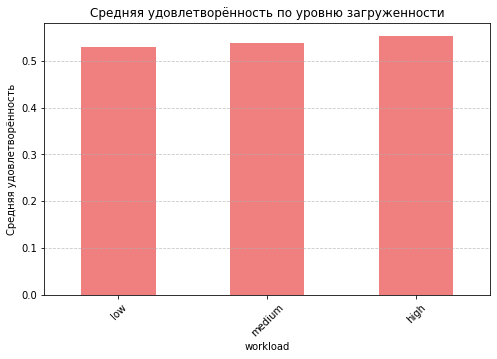

In [119]:
plt.figure(figsize=(8, 5))
mean_satisfaction_by_workload.reindex(workload_order).plot(kind='bar', color='lightcoral')
plt.title('Средняя удовлетворённость по уровню загруженности')
plt.ylabel('Средняя удовлетворённость')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [120]:
train_quit_clone = train_quit.copy()
workload_mapping = {'low': 1, 'medium': 2, 'high': 3}
train_quit_clone['workload_numeric'] = train_quit_clone['workload'].map(workload_mapping)

# Проверяем, что всё правильно закодировалось
print("Уникальные значения workload_numeric:")
print(train_quit_clone['workload_numeric'].unique())

Уникальные значения workload_numeric:
[3 2 1]


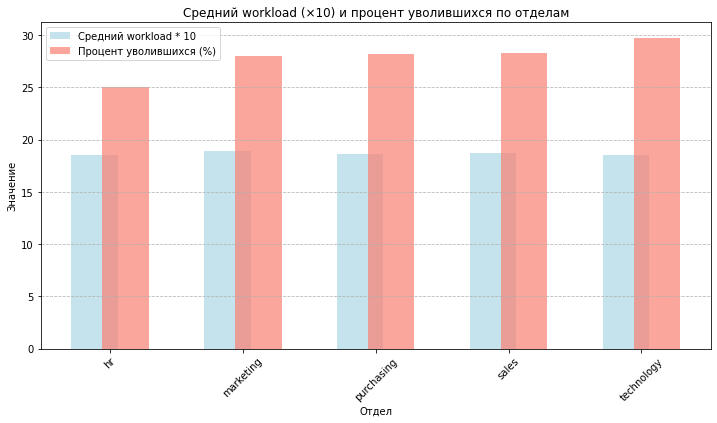

In [121]:
# Рассчитываем среднее числовое значение workload_numeric для каждого отдела и умножаем на 10
mean_workload_by_dept = train_quit_clone.groupby('dept')['workload_numeric'].mean() * 10

# Процент уволившихся по отделам (уже есть)
quit_percentage_by_dept = (train_quit[train_quit['quit'] == 'yes'].groupby('dept').size() /
                           train_quit.groupby('dept').size() * 100).reindex(dept_order)

# Подготовка данных для графика
dept_order = ['hr', 'marketing', 'purchasing', 'sales', 'technology']
mean_workload_by_dept = mean_workload_by_dept.reindex(dept_order)

# Ширина столбцов и сдвиг
bar_width = 0.35
x = np.arange(len(dept_order))

# График
plt.figure(figsize=(12, 6))

# Столбцы для среднего workload_numeric * 10 (сдвинуты влево)
bars1 = plt.bar(x - bar_width/3, mean_workload_by_dept, width=bar_width,
               color='lightblue', alpha=0.7, label='Средний workload * 10')

# Столбцы для процента уволившихся (сдвинуты вправо)
bars2 = plt.bar(x + bar_width/3, quit_percentage_by_dept, width=bar_width,
               color='salmon', alpha=0.7, label='Процент уволившихся (%)')

# Настройки осей и меток
plt.xlabel('Отдел')
plt.ylabel('Значение')
plt.title('Средний workload (×10) и процент уволившихся по отделам')
plt.xticks(x, dept_order, rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.9)

# Легенда
plt.legend()

plt.show()

<div style="background-color: white; color: olive;">
    Я выше рассмотрел нагруженность, приняв low за 1, medium за 2 и high за 3 условные рабочие единицы в нагрузке.Так как видов значений у нас мало (три), то я смотрел на среднее значение, а не на медианное. Видно, что % уволившихся по отделам относительно одинаковый, как и уровень загруженности, но выводов, сделанных мною выше, это не отменяет!
</div>

## Корреляционный анализ данных 2

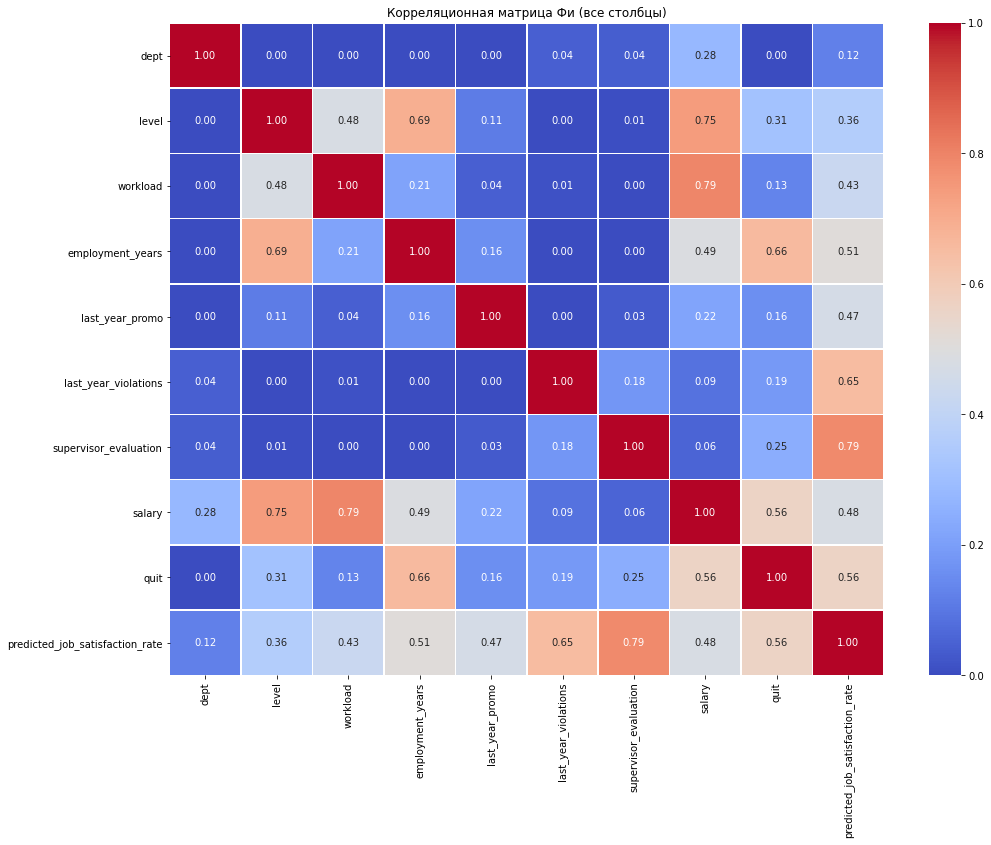

Пары признаков со значимой корреляцией:
employment_years и level: 0.69
salary и level: 0.75
salary и workload: 0.79
quit и employment_years: 0.66
predicted_job_satisfaction_rate и last_year_violations: 0.65
predicted_job_satisfaction_rate и supervisor_evaluation: 0.79


In [122]:
# Указываем интервальные столбцы (непрерывные признаки)
interval_cols = ['salary', 'predicted_job_satisfaction_rate']

# Вычисляем корреляционную матрицу Фи для ВСЕХ столбцов
phik_corr_matrix = train_quit.phik_matrix(interval_cols=interval_cols)

# Визуализация
plt.figure(figsize=(16, 12))
sns.heatmap(phik_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Корреляционная матрица Фи (все столбцы)')
plt.show()

# Анализ мультиколлинеарности
high_corr_pairs = []
for i in range(len(phik_corr_matrix.columns)):
    for j in range(i):
        if abs(phik_corr_matrix.iloc[i, j]) > 0.6:
            pair = (phik_corr_matrix.columns[i], phik_corr_matrix.columns[j], phik_corr_matrix.iloc[i, j])
            high_corr_pairs.append(pair)

print("Пары признаков со значимой корреляцией:")
for pair in high_corr_pairs:
    print(f"{pair[0]} и {pair[1]}: {pair[2]:.2f}")

<div style="background-color: white; color: olive;">
    Вроде бы, всё хорошо, но излишняя корреляция predicted_job_satisfaction_rate и supervisor_evaluation меня настораживает.
</div>

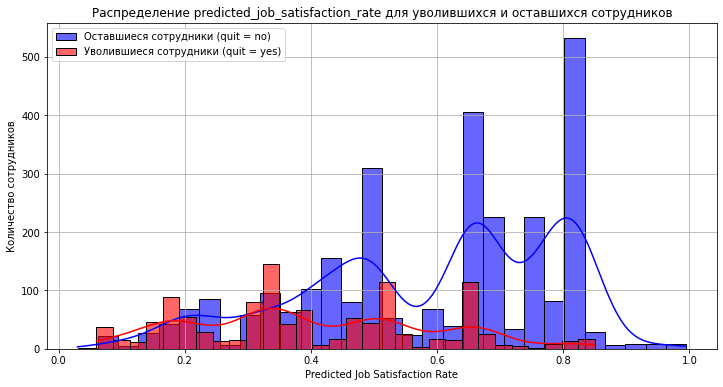

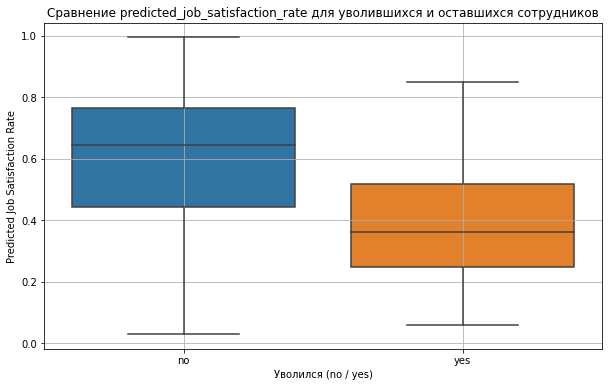

Результаты теста Манна-Уитни:
U-статистика: 2432021.5
p-value: 6.9682040455063e-135
Вывод: Распределения удовлетворённости от работы для уволившихся и оставшихся сотрудников статистически значимо различаются (p < 0.05).


In [123]:
# Разделяем данные на две группы: уволившиеся (quit = 'yes') и оставшиеся (quit = 'no')
quit_yes = train_quit[train_quit['quit'] == 'yes']['predicted_job_satisfaction_rate']
quit_no = train_quit[train_quit['quit'] == 'no']['predicted_job_satisfaction_rate']

# Визуализация распределений
plt.figure(figsize=(12, 6))

# Гистограммы
sns.histplot(quit_no, bins=30, color='blue', label='Оставшиеся сотрудники (quit = no)', kde=True, alpha=0.6)
sns.histplot(quit_yes, bins=30, color='red', label='Уволившиеся сотрудники (quit = yes)', kde=True, alpha=0.6)

plt.title('Распределение predicted_job_satisfaction_rate для уволившихся и оставшихся сотрудников')
plt.xlabel('Predicted Job Satisfaction Rate')
plt.ylabel('Количество сотрудников')
plt.legend()
plt.grid(True)
plt.show()

# Boxplot для сравнения распределений
plt.figure(figsize=(10, 6))
sns.boxplot(x='quit', y='predicted_job_satisfaction_rate', data=train_quit)
plt.title('Сравнение predicted_job_satisfaction_rate для уволившихся и оставшихся сотрудников')
plt.xlabel('Уволился (no / yes)')
plt.ylabel('Predicted Job Satisfaction Rate')
plt.grid(True)
plt.show()

# Статистический тест (тест Манна-Уитни)
u_statistic, p_value = stats.mannwhitneyu(quit_no, quit_yes, alternative='two-sided')

print(f"Результаты теста Манна-Уитни:")
print(f"U-статистика: {u_statistic}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Вывод: Распределения удовлетворённости от работы для уволившихся и оставшихся сотрудников статистически значимо различаются (p < 0.05).")
else:
    print("Вывод: Нет статистически значимых различий между распределениями (p >= 0.05).")

<div style="background-color: white; color: olive;">
    1) Большое значение U-статистики = значимое различие между группами;
    <br/>
    2) P-value серьёзно меньше 0.05, что подтверждает значимость различий между распределениями и говорит о том, что вероятность того, что такие различия возникли случайно, минимальна;
    <br/>
    3) Распределения ожидаемого (предсказанного) уровня удовлетворённости сотрудника для уволившихся и оставшихся сотрудников статистически значимо различаются. Это подтверждает, что уровень удовлетворённости работой влияет на решение сотрудника уволиться.
</div>

## Использование пайплайнов 2

In [124]:
train_quit.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4000 entries, 723290 to 853842
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   dept                             4000 non-null   object 
 1   level                            4000 non-null   object 
 2   workload                         4000 non-null   object 
 3   employment_years                 4000 non-null   int64  
 4   last_year_promo                  4000 non-null   object 
 5   last_year_violations             4000 non-null   object 
 6   supervisor_evaluation            4000 non-null   int64  
 7   salary                           4000 non-null   int64  
 8   quit                             4000 non-null   object 
 9   predicted_job_satisfaction_rate  4000 non-null   float64
dtypes: float64(1), int64(3), object(6)
memory usage: 472.8+ KB


In [125]:
numerical_features = train_quit.drop(
    columns=[
             'employment_years',
             'salary'
            ]
).select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = train_quit.drop(
    columns=[
             'quit'
            ]
).select_dtypes(include=['object']).columns.tolist()

In [127]:
# Определяем метрики
scoring = {
    'roc_auc': 'roc_auc',
    'f1': make_scorer(f1_score, average='weighted'),
    'precision': make_scorer(precision_score, average='weighted'),
    'recall': make_scorer(recall_score, average='weighted')
}

# Разделяем признаки на три категории
ordinal_features = ['level', 'workload']
categorical_features_ohe = ['dept', 'last_year_promo', 'last_year_violations']
numerical_features = ['supervisor_evaluation', 'predicted_job_satisfaction_rate', 'salary', 'employment_years']

# Разделяем данные на X и y (весь датасет train_quit)
X = train_quit.drop(columns=['quit'])
y = train_quit['quit']

# Кодируем целевую переменную quit с помощью LabelEncoder
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)  # Обучаем на всех данных

# Проверяем, как закодировались метки
print("Кодирование меток для quit:")
print(dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

# Преобразуем количественные признаки
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Преобразуем категориальные признаки с OneHotEncoder
categorical_transformer_ohe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Преобразуем категориальные признаки с OrdinalEncoder
categorical_transformer_oe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

# Объединяем трансформации
preprocessor_ohe = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat_ohe', categorical_transformer_ohe, categorical_features_ohe),
        ('cat_oe', categorical_transformer_oe, ordinal_features)
    ]
)

preprocessor_oe = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat_ohe', categorical_transformer_ohe, categorical_features_ohe),
        ('cat_oe', categorical_transformer_oe, ordinal_features)
    ]
)

# Обновляем y на закодированные значения
y = y_encoded

# Пайплайны для моделей
pipeline_lr = Pipeline(steps=[
    ('preprocessor', preprocessor_ohe),
    ('classifier', LogisticRegression(random_state=42))
])

pipeline_knn = Pipeline(steps=[
    ('preprocessor', preprocessor_ohe),
    ('classifier', KNeighborsClassifier())
])

pipeline_dt = Pipeline(steps=[
    ('preprocessor', preprocessor_oe),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor_oe),
    ('classifier', RandomForestClassifier(random_state=42))
])

pipeline_gb = Pipeline(steps=[
    ('preprocessor', preprocessor_oe),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

# Гиперпараметры для моделей
param_grid_lr = {'classifier__C': [0.1, 1, 10]}
param_grid_knn = {'classifier__n_neighbors': [3, 5, 7]}
param_grid_dt = {'classifier__max_depth': [3, 5, 7]}
param_grid_rf = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5]
}
param_grid_gb = {
    'classifier__n_estimators': [100, 200],
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__max_depth': [3, 5, 7]
}

# Подбор гиперпараметров с метриками
grid_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=5, scoring=scoring, refit='roc_auc')
grid_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=5, scoring=scoring, refit='roc_auc')
grid_dt = GridSearchCV(pipeline_dt, param_grid_dt, cv=5, scoring=scoring, refit='roc_auc')
grid_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=5, scoring=scoring, refit='roc_auc')
grid_gb = GridSearchCV(pipeline_gb, param_grid_gb, cv=5, scoring=scoring, refit='roc_auc')

# Обучение моделей на всей обучающей выборке
grid_lr.fit(X, y)
grid_knn.fit(X, y)
grid_dt.fit(X, y)
grid_rf.fit(X, y)
grid_gb.fit(X, y)

Кодирование меток для quit:
{'no': 0, 'yes': 1}


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['supervisor_evaluation',
                                                                          'predicted_job_satisfaction_rate',
                                                                          'salary',
                                                                          'employment_years']),
                    

## Определяем лучшую модель 2

In [128]:
best_models = {
    'Logistic Regression': (grid_lr.best_score_, grid_lr.best_estimator_),
    'KNN': (grid_knn.best_score_, grid_knn.best_estimator_),
    'Decision Tree': (grid_dt.best_score_, grid_dt.best_estimator_),
    'Random Forest': (grid_rf.best_score_, grid_rf.best_estimator_),
    'Gradient Boosting': (grid_gb.best_score_, grid_gb.best_estimator_)
}

# Находим модель с наибольшим best_score_ (ROC-AUC нужно максимизировать)
best_model_name, (best_score, best_estimator) = max(best_models.items(), key=lambda x: x[1][0])
print(f"Лучшая модель: {best_model_name} с best_score (ROC-AUC): {best_score}")

# Сохраняем лучшую модель для дальнейшего использования
best_estimator_classification = best_estimator

print('Лучшая модель и её параметры:\n\n', best_estimator)

Лучшая модель: Gradient Boosting с best_score (ROC-AUC): 0.9420852410699668
Лучшая модель и её параметры:

 Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['supervisor_evaluation',
                                                   'predicted_job_satisfaction_rate',
                                                   'salary',
                                                   'employment_years']),
                                                 ('cat_ohe',
                                                  Pipeline(steps=[('imputer',
                      

<div style="background-color: white; color: olive;">
    Как хорошо, что я не работал прямо с файлом test_features, меняя всё в нём вверх дном! Теперь можно смело объединять его с новыми данными по индексам, сделаю это по ID, а после уберу ID в индекс.
</div>

In [130]:
test_data_quit = test_features.merge(test_target_quit, on='id', how='left')
test_data_quit.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   id                     2000 non-null   int64 
 1   dept                   1997 non-null   object
 2   level                  1999 non-null   object
 3   workload               1999 non-null   object
 4   employment_years       2000 non-null   int64 
 5   last_year_promo        2000 non-null   object
 6   last_year_violations   2000 non-null   object
 7   supervisor_evaluation  2000 non-null   int64 
 8   salary                 2000 non-null   int64 
 9   quit                   2000 non-null   object
dtypes: int64(4), object(6)
memory usage: 171.9+ KB


In [131]:
# Подготовка данных для предсказания job_satisfaction_rate
X_quit_for_job_satisfaction = test_data_quit.drop(columns=['quit'])

# Убедимся, что используем только те столбцы, которые были в X для регрессии
features_for_regression = [col for col in X.columns if col in X_quit_for_job_satisfaction.columns and col != 'predicted_job_satisfaction_rate']
X_quit_for_job_satisfaction = X_quit_for_job_satisfaction[features_for_regression]

# Предсказываем значения job_satisfaction_rate
job_satisfaction_predictions = best_estimator_regression.predict(X_quit_for_job_satisfaction)
test_data_quit['predicted_job_satisfaction_rate'] = job_satisfaction_predictions

In [132]:
# Подготовка данных для предсказания quit
X_quit_for_classification = test_data_quit.drop(columns=['quit'])

# Убедимся, что используем только те столбцы, которые были в X для классификации
features_for_classification = [col for col in X.columns if col in X_quit_for_classification.columns]
X_quit_for_classification = X_quit_for_classification[features_for_classification]

# Предсказываем вероятности и классы для quit
quit_predictions_proba = best_estimator_classification.predict_proba(X_quit_for_classification)[:, 1]
quit_predictions_encoded = best_estimator_classification.predict(X_quit_for_classification)

# Декодируем предсказания обратно в 'no'/'yes'
quit_predictions = label_encoder.inverse_transform(quit_predictions_encoded)

# Добавляем предсказания в test_data_quit
test_data_quit['predicted_quit_proba'] = quit_predictions_proba
test_data_quit['predicted_quit'] = quit_predictions

# Сравниваем предсказания с реальными значениями
y_real = test_data_quit['quit']

# Выводим отчет о классификации
print("Classification Report:")
print(classification_report(y_real, quit_predictions))

# Рассчитываем ROC-AUC
test_roc_auc = roc_auc_score(label_encoder.transform(y_real), quit_predictions_proba)
print(f"ROC-AUC на тестовом наборе: {test_roc_auc}")

# Показываем первые несколько строк с предсказаниями
display(test_data_quit.head(10))

Classification Report:
              precision    recall  f1-score   support

          no       0.94      0.93      0.94      1436
         yes       0.83      0.86      0.84       564

    accuracy                           0.91      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.91      0.91      0.91      2000

ROC-AUC на тестовом наборе: 0.9288421837649894


,id,dept,level,workload,employment_years,last_year_promo,last_year_violations,supervisor_evaluation,salary,quit,predicted_job_satisfaction_rate,predicted_quit_proba,predicted_quit
0,485046,marketing,junior,medium,2,no,no,5,28800,no,0.833855,0.039905,no
1,686555,hr,junior,medium,1,no,no,4,30000,no,0.673434,0.064499,no
2,467458,sales,middle,low,5,no,no,4,19200,no,0.664074,0.039195,no
3,418655,sales,middle,low,6,no,no,4,19200,no,0.664074,0.039195,no
4,789145,hr,middle,medium,5,no,no,5,40800,no,0.807181,0.016429,no
5,429973,purchasing,middle,medium,6,no,no,3,42000,yes,0.489588,0.015706,no
6,850699,technology,junior,medium,3,no,no,3,26400,yes,0.386538,0.843792,yes
7,500791,sales,middle,high,9,no,no,4,49200,no,0.765798,0.024443,no
8,767867,marketing,middle,high,3,no,yes,4,62400,no,0.360000,0.084012,no
9,937235,sales,junior,medium,1,no,yes,3,26400,yes,0.155000,0.914676,yes


<div style="background-color: white; color: olive;">
    Успех! Показатель ROC-AUC на тестовом наборе крайне хороший, что говорит о высоком качестве как второй (предсказания ухода), так и первой (рассчёт удовлетворённости) моделей.
</div>

## Промежуточные выводы 2

<div style="background-color: white; color: olive;">
    Почему именно Gradient Boosting хорошо себя показал?!
<br/>
    <br/>
    Посмею предположить, что это связано с наличием сложных нелинейных зависимостей, которые улавливаются данной моделью.
<br/>
    <br/>
    Данная модель устойчива к шуму и выбросам (т.е. моим кривым рукам).
<br/>
    <br/>
    ВОЗМОЖНО! Я не так уж и плохо предобработал данные + явная корреляция с predicted_job_satisfaction_rate помогает точнее определить категориальную переменную.
</div>

## Финальные выводы

<div style="background-color: #faf4ff; border: 8px solid #d3aae3; border-radius: 8px; padding: 15px; margin: 10px 0; font-weight: bold;">
  Итак, что было сделано?
<br/>
    <br/>
    Данные были рассмотрены и проанализированы;
<br/> 
    Затем были сделаны промежуточные выводы и построена модель для предсказания удовлетворённости сотрудников;
<br/>
    После чего были рассмотрены и проанализированы данные о связи увольнений с прочими параметрами;
<br/>
    В том числе, на предыдущем шаге использовались предсказанные значения удовлетворённости сотрудников;
<br/>
    После чего была создана модель предсказания увольнения сотрудников;
<br/>
    Стоит взять во внимание, что модель для предсказания увольнения строится на базисе модели предсказания удовлетворённости сотрудников.
<br/>
    <br/>
        <br/>
   В данных присутствует очень интересная зависимость между оценкой качества работы сотрудника, которую дал руководитель, и удовлетворённостью сотрудника. Думаю, этот момент будет крайне интересно рассмотреть в будущих исследованиях, а именно задаться следующими вопросами:
<br/>
    <br/>
    Знают ли сотрудники, какую оценку им дал руководитель?
<br/>
    Знают ли сотрудники, какую оценку дали руководители другим сотрудникам?
<br/>
    Насколько данная оценка выражается явно и какие бенефиции она даёт?
<br/>
    <br/>
        <br/>
            Это на подумать, просто интересно:)
</div>